In [34]:
import pandas as pd
import numpy as np
import yfinance as yf

import plotting_functions as pf
import backtesting_functions as bf

from statsmodels.tsa.stattools import adfuller, kpss
import matplotlib.pyplot as plt

import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter('ignore', InterpolationWarning)
warnings.filterwarnings("ignore", message=r".*inplace keyword in DataFrame\..*")



In [35]:
'''Importing the data generated from DATA_prep.ipynb'''
def clean_import(df):
    df = df.drop(columns='Unnamed: 0')
    df['Date'] = pd.to_datetime(df['Date'])
    return df

train_data = clean_import(pd.read_csv('Data/Transformed_Sector_data_train.csv'))
test_data = clean_import(pd.read_csv('Data/Transformed_Sector_data_test.csv'))
all_data = clean_import(pd.read_csv('Data/Transformed_Sector_data_all.csv'))

prices = (all_data.assign(Date=pd.to_datetime(all_data['Date'])).pivot(index='Date', columns='Ticker', values='Close').sort_index().ffill())

In [ ]:
'''Initialise constants, and entry and exit conditions'''
COST_BSP = 5
TRAIL_ATR = 1
RISK = 0.025
MAX_LEVERAGE = 2

# Conditions: (d, t) for entry, (d, t, i) for exit, where t = current bar, i = entry bar
entry_fn = lambda d, t: d['Stage2_Heatmap_Slope'][t] == 1
# entry_fn = lambda d, t: d['Stage2'][t] == 1

# exit_fn = lambda d, t, i: (d['Stage'][t] != 2) #Non-Stage 2 
exit_fn = lambda d, t, i: (d['Stage'][t] != 2 or d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Non-Stage 2 and Trailing Stop
# exit_fn = lambda d, t, i: (d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Only Trailing Stop


# HEATMAP SPIKE (TRAIN)

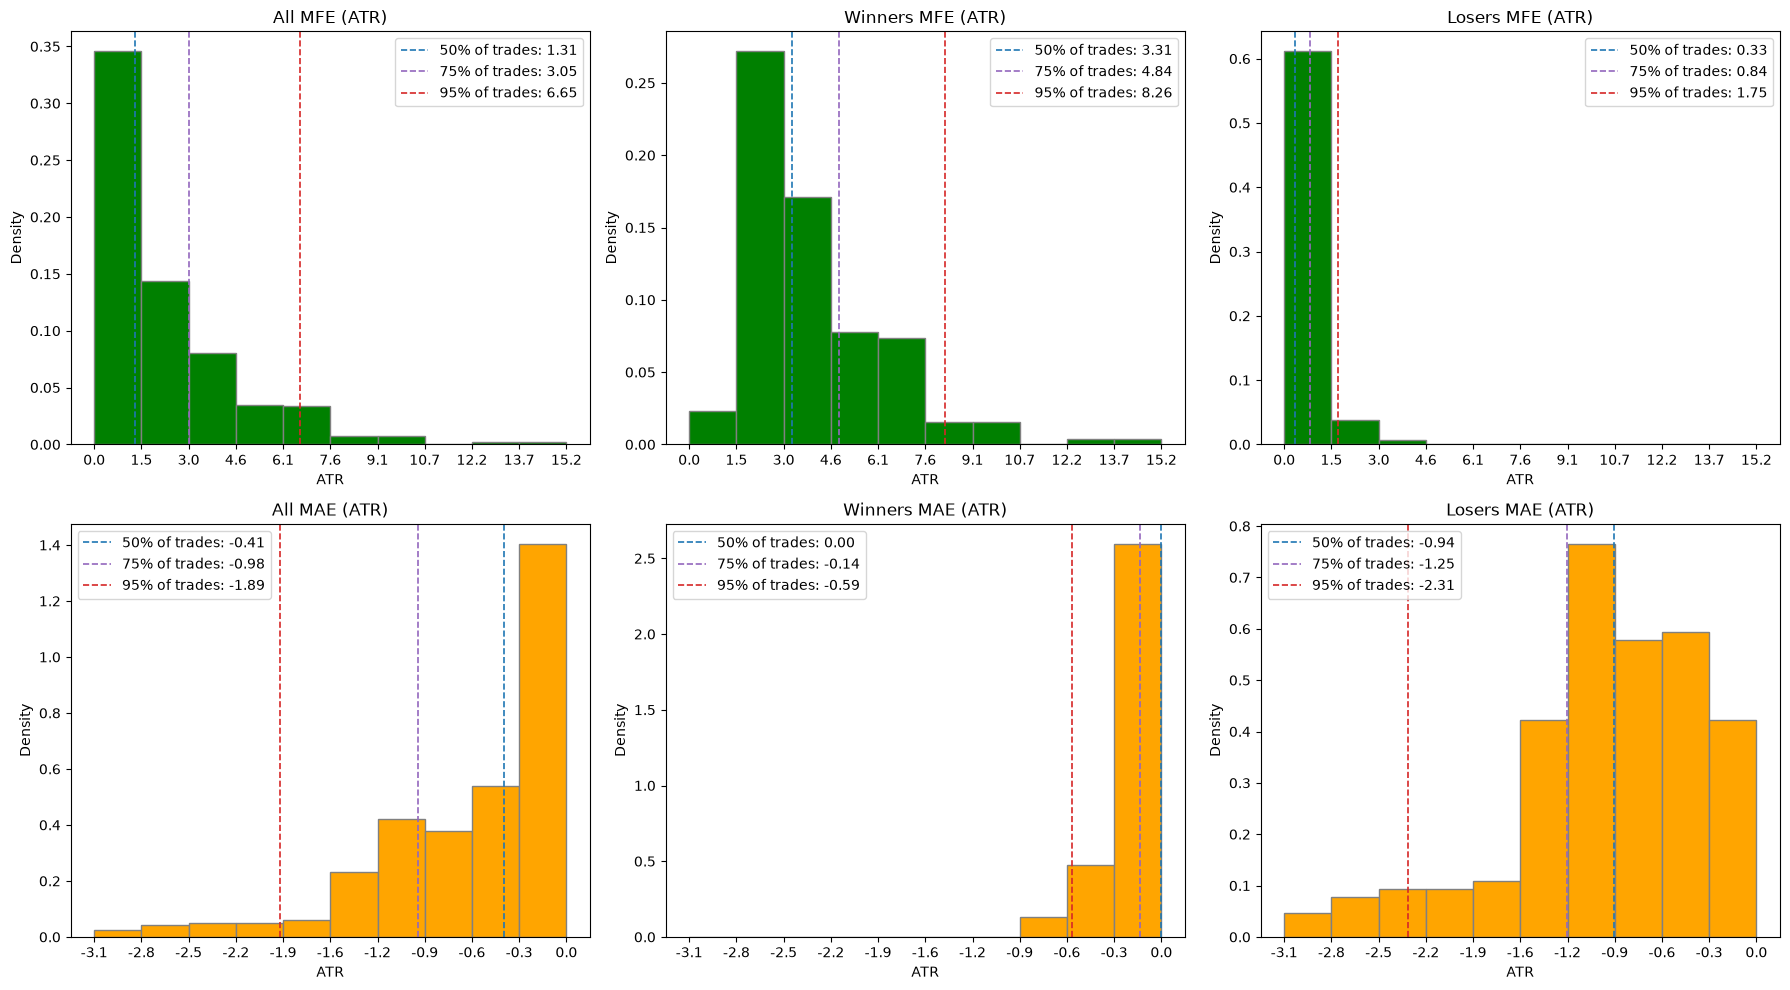

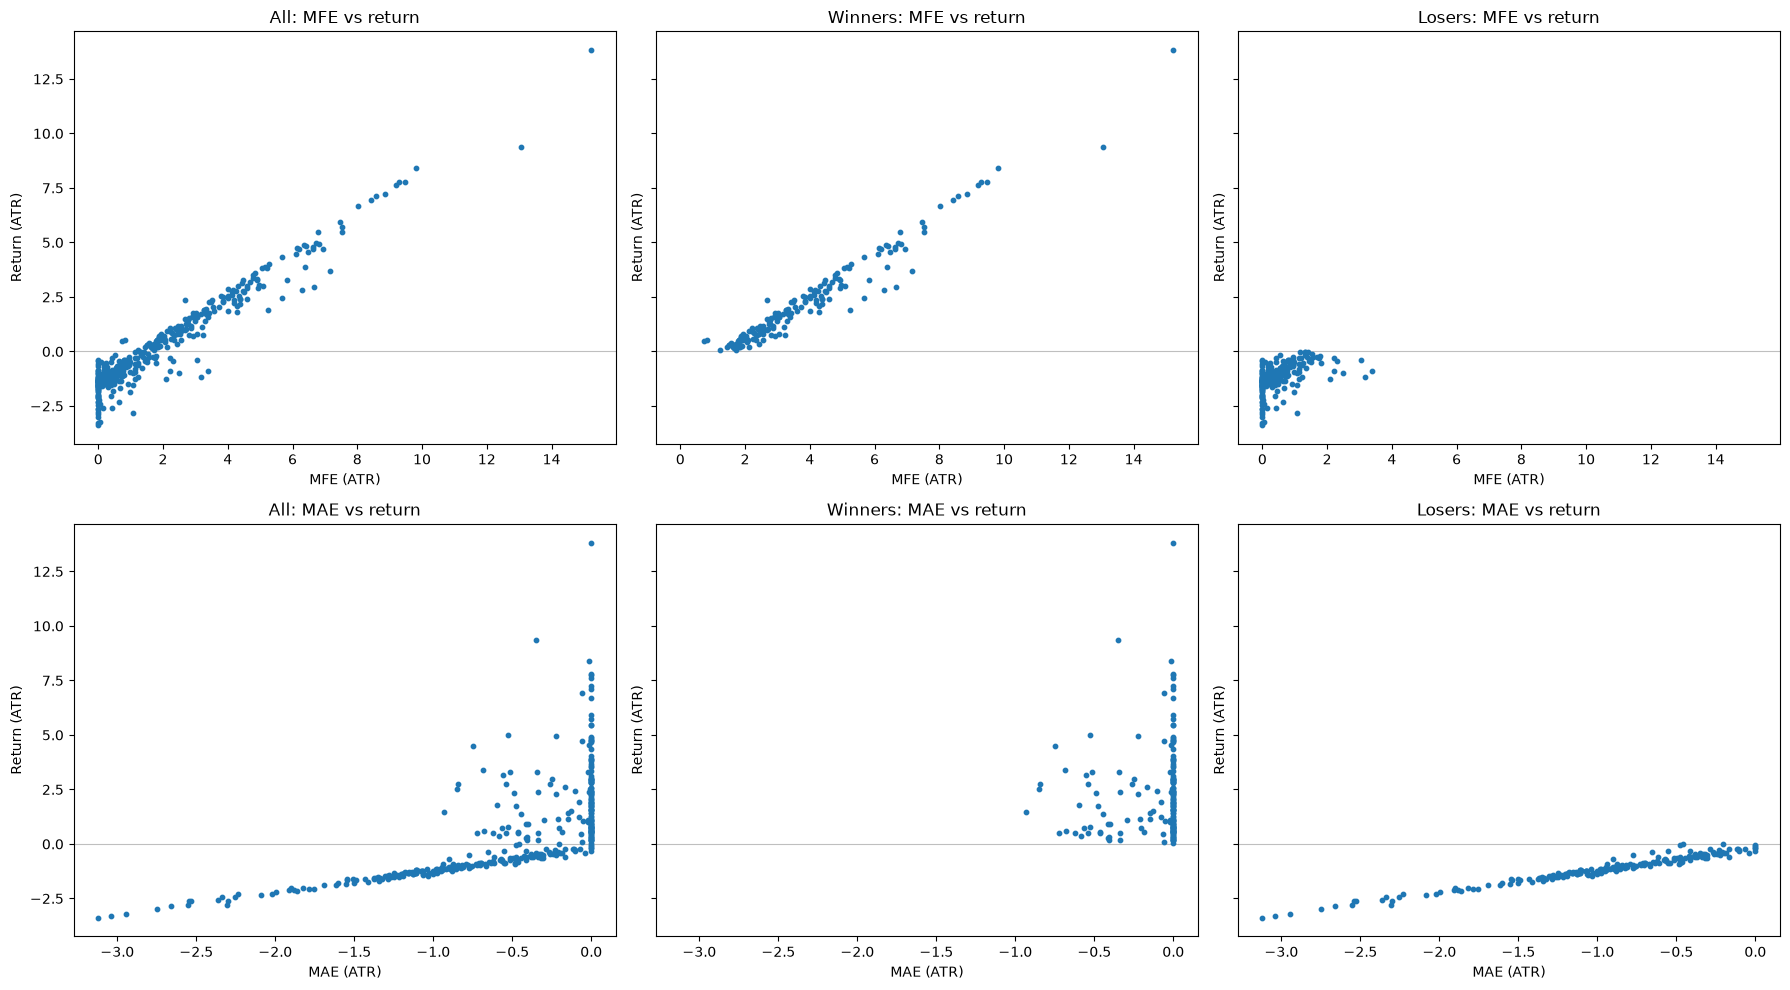

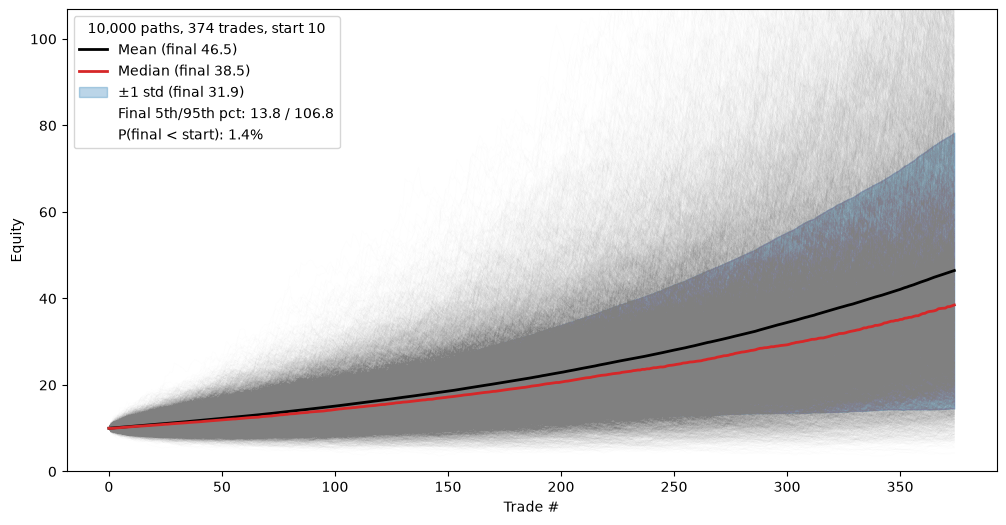

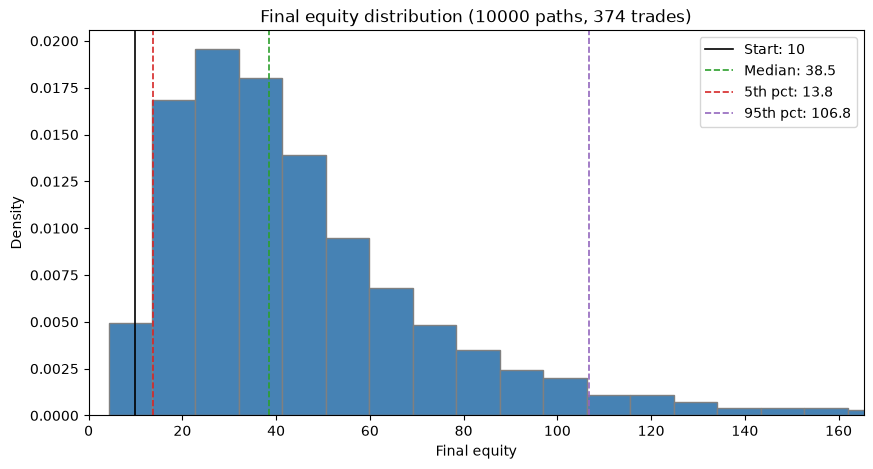

P(loss): 1.4%


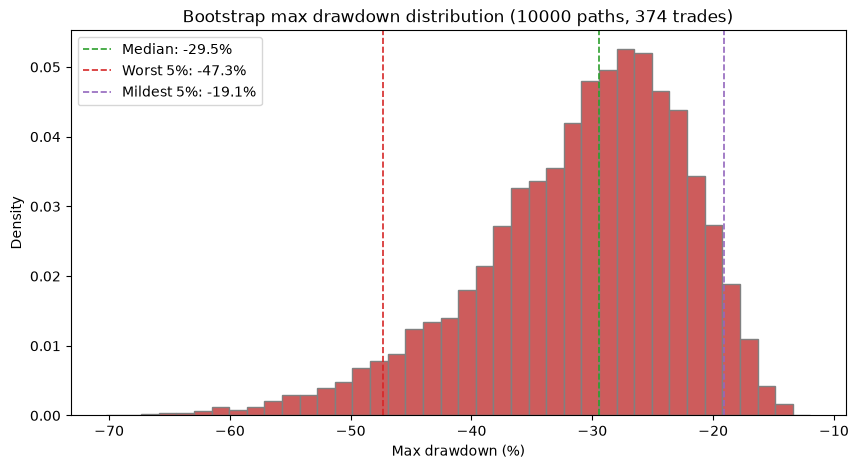

P(maxDD worse than -20%): 92.7%
MaxDD -26.6% on 2020-06-24 | Longest underwater 603d | Median episode 6d | Time underwater 93% | Currently 179d under


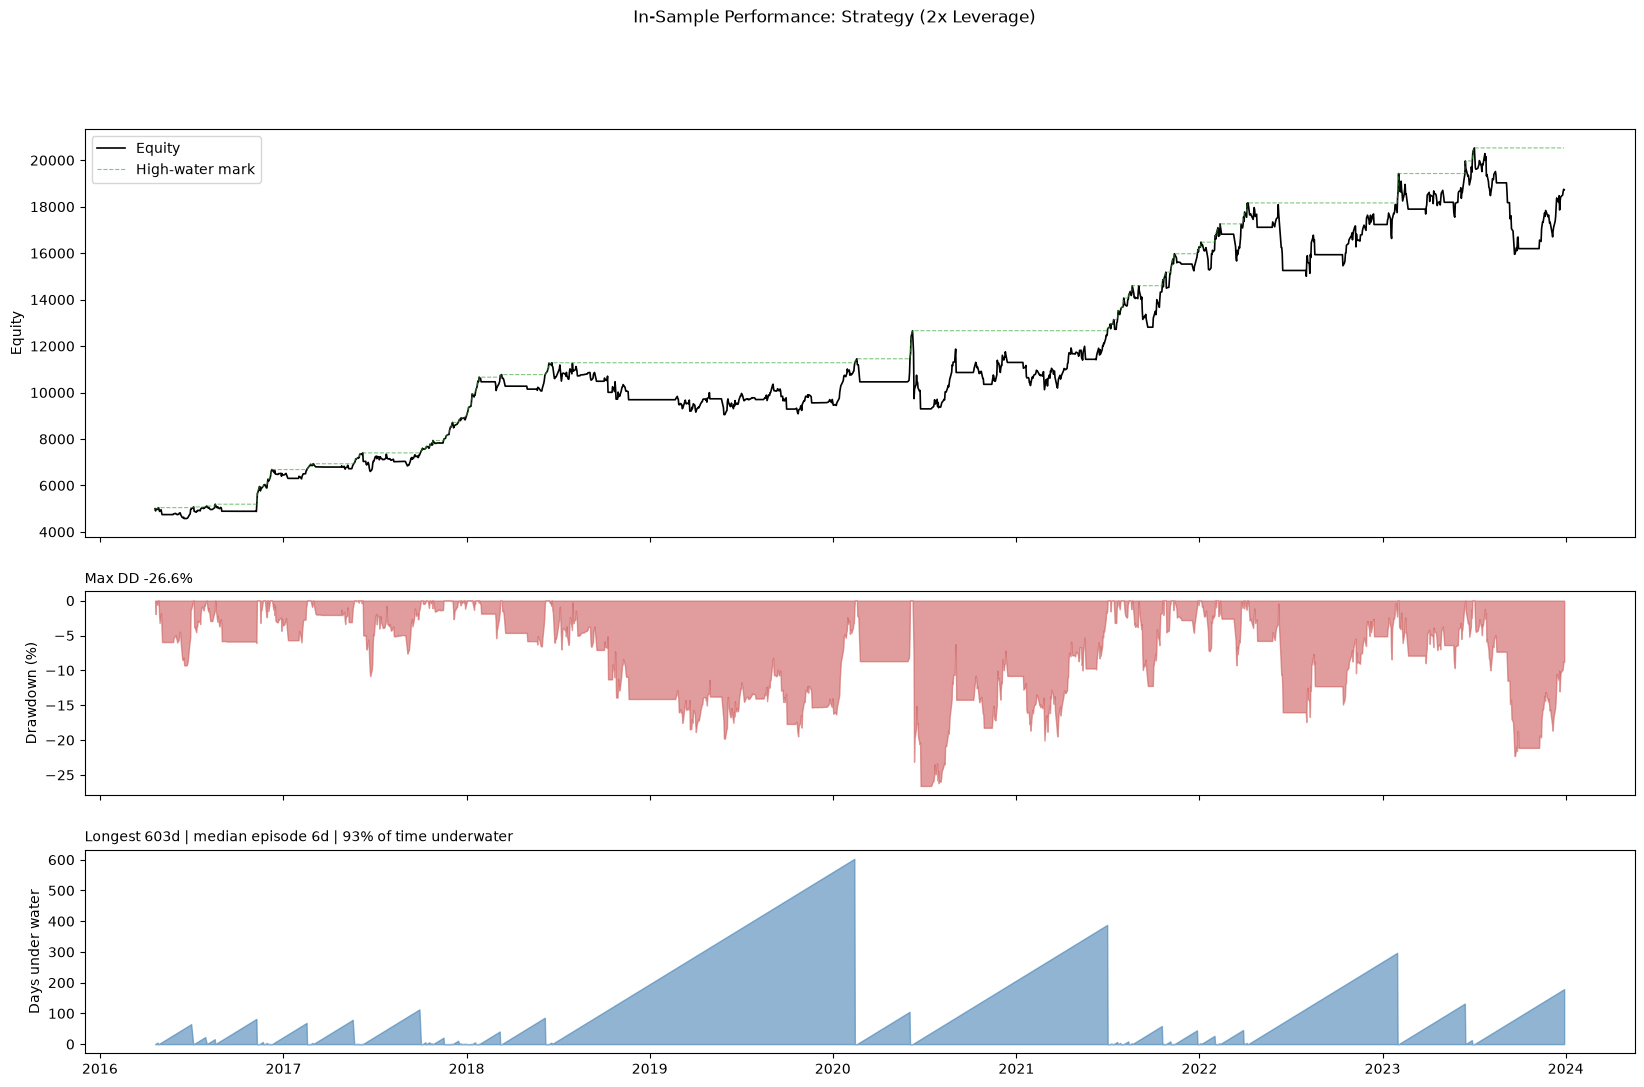

Total return (%)            274.58
CAGR (%)                     18.73
Ann. vol (%)                 21.35
Sharpe                        0.91
Sortino                       1.27
Max DD (%)                  -26.58
Calmar                        0.70
Max DD duration (d)         389.00
Longest underwater (d)      603.00
Time underwater (%)          93.09
Signals                     374.00
Trades filled               298.00
Skipped, no capacity (%)     20.32
Win rate (%)                 46.31
Profit factor                 1.55
Payoff (avg W / avg L)        1.79
Expectancy (R)                0.20
Days in market (%)           66.00
Peak leverage (x)             2.00
rho = 0.3294521375883555
S_i = 0.7645066551628856
rho*S_p = 0.30074457193624626
W_i = 0.4482375964489672
                          Strategy     SPY     Mix
Ann. vol (%)                 21.35   18.44   16.47
CAGR (%)                     18.73   13.18   16.99
Calmar                        0.70    0.39    0.84
Days in market (%)        

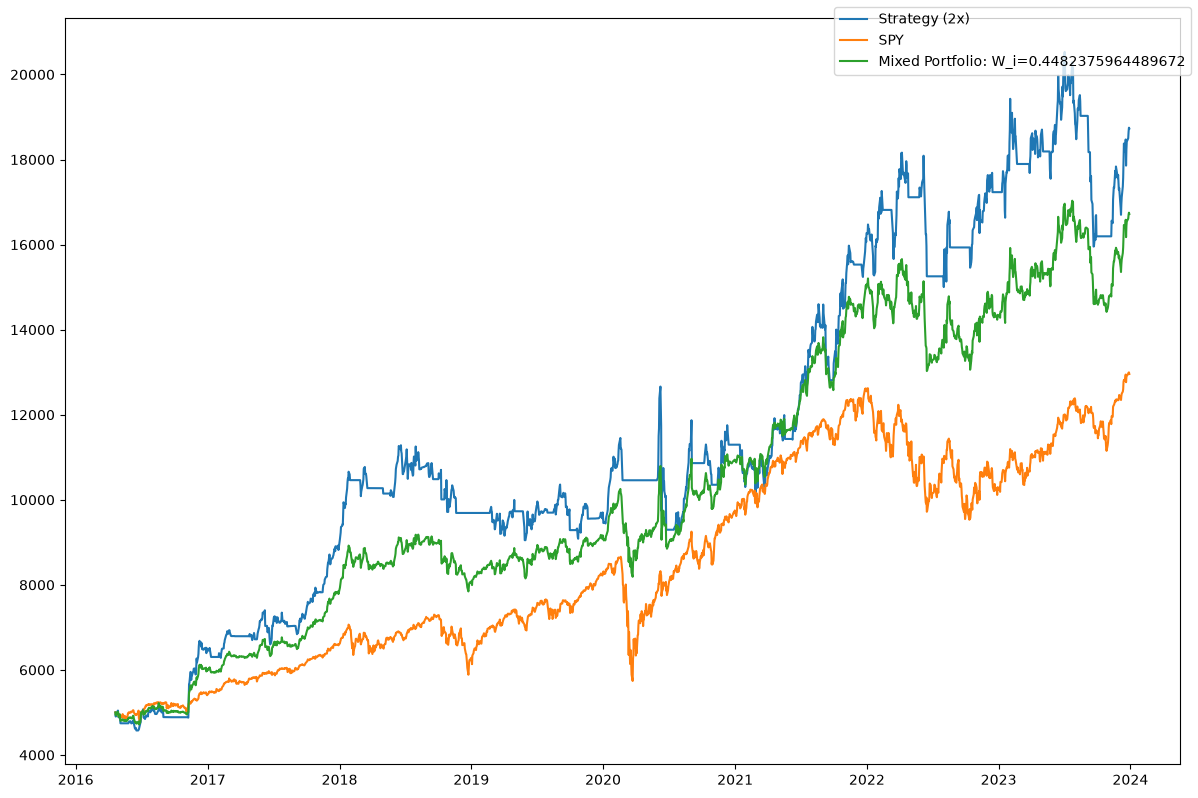

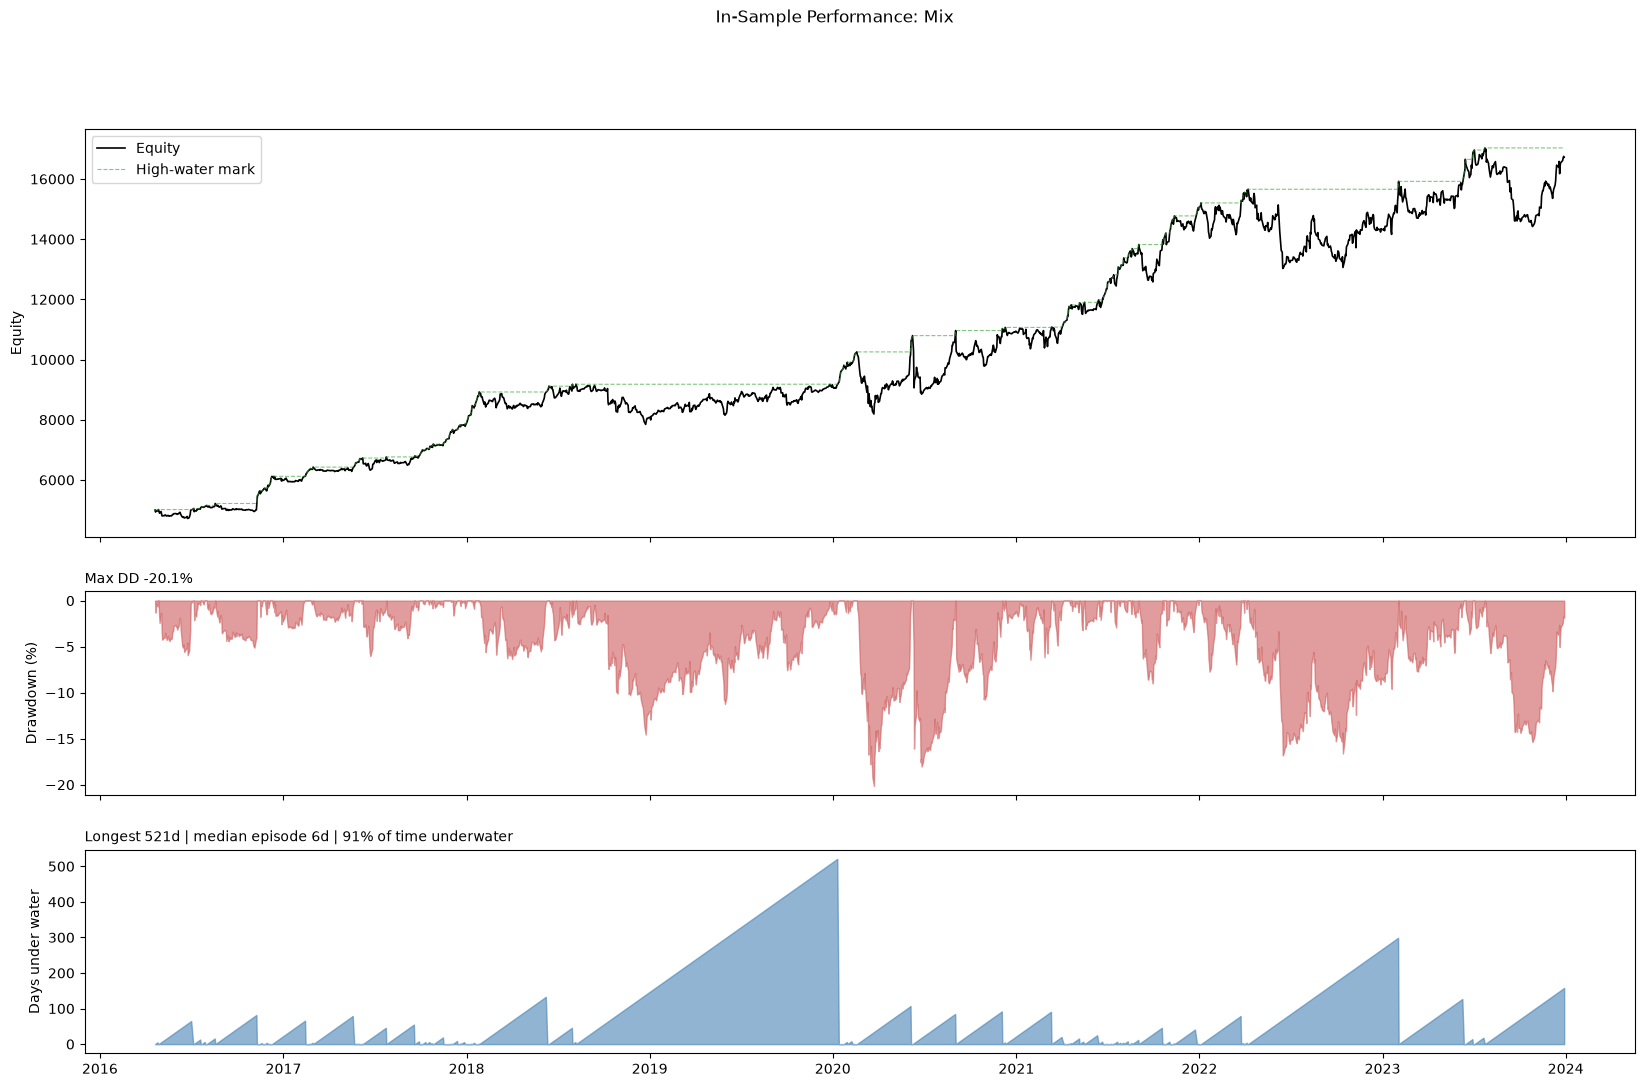

In [37]:
df = train_data
trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = f'In-Sample Performance: Strategy ({MAX_LEVERAGE}x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

train_W_i = bf.SPY_combo(daily,t,is_train=True,title='In-Sample Performance: Mix')

# HEATMAP SPIKE (TEST)

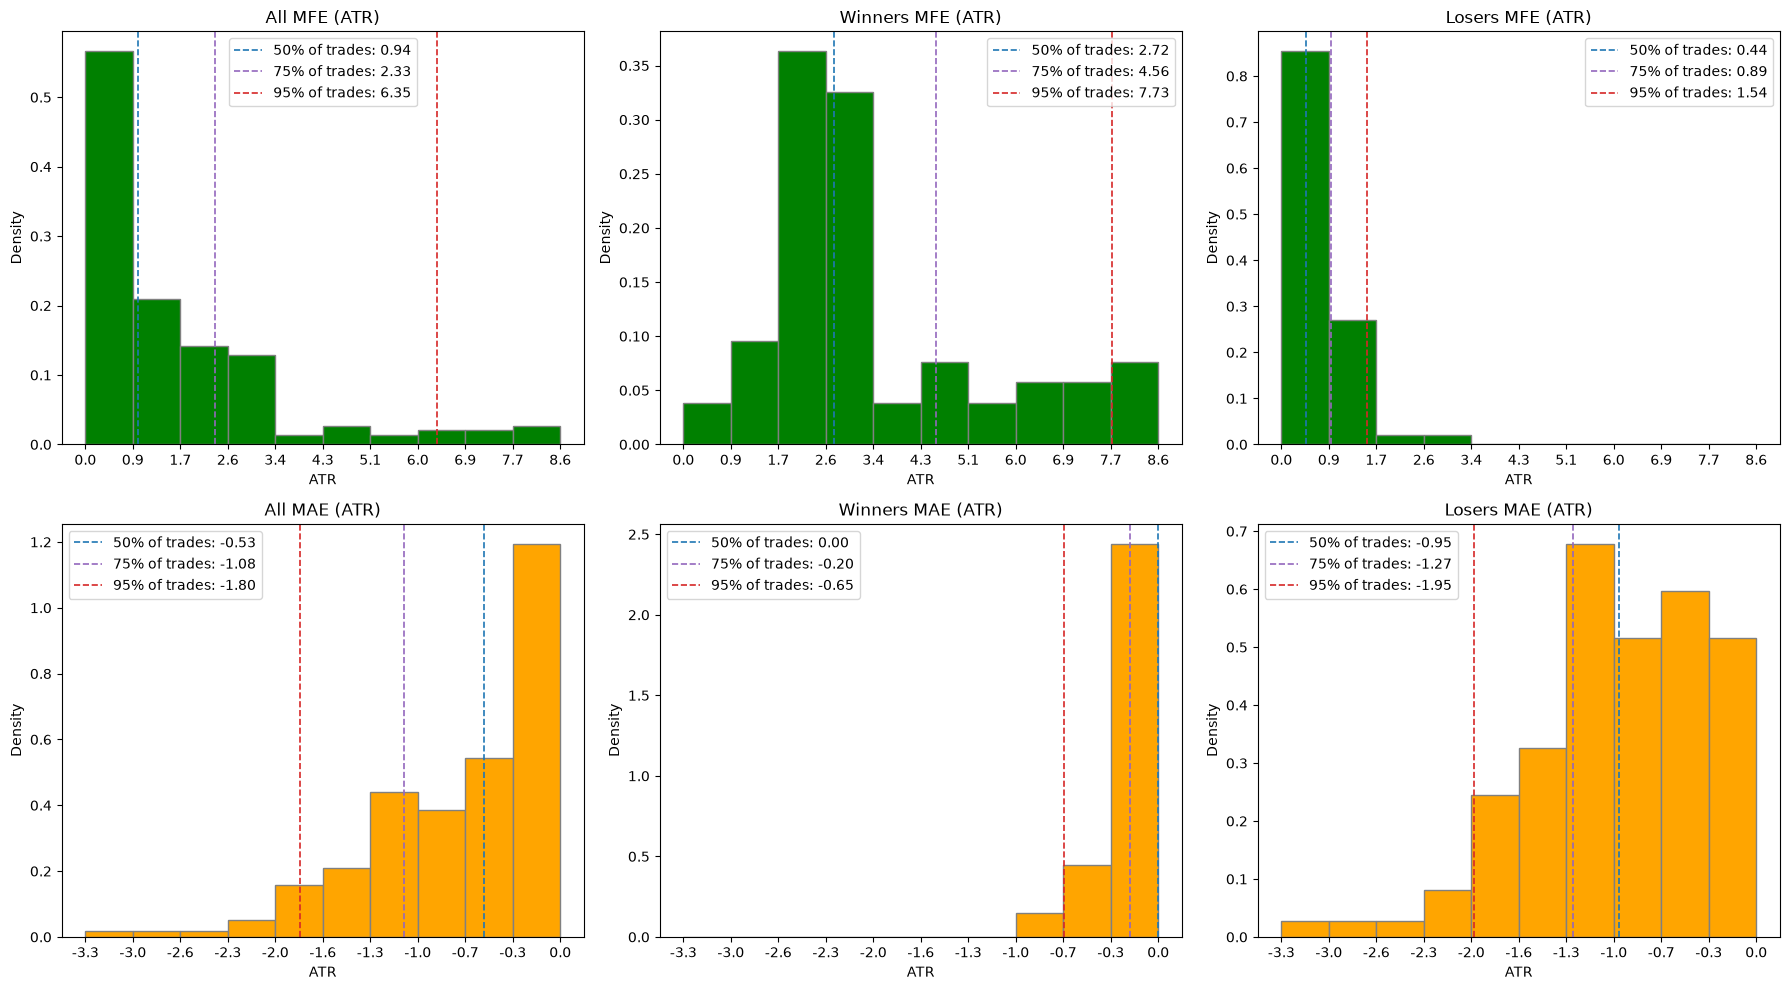

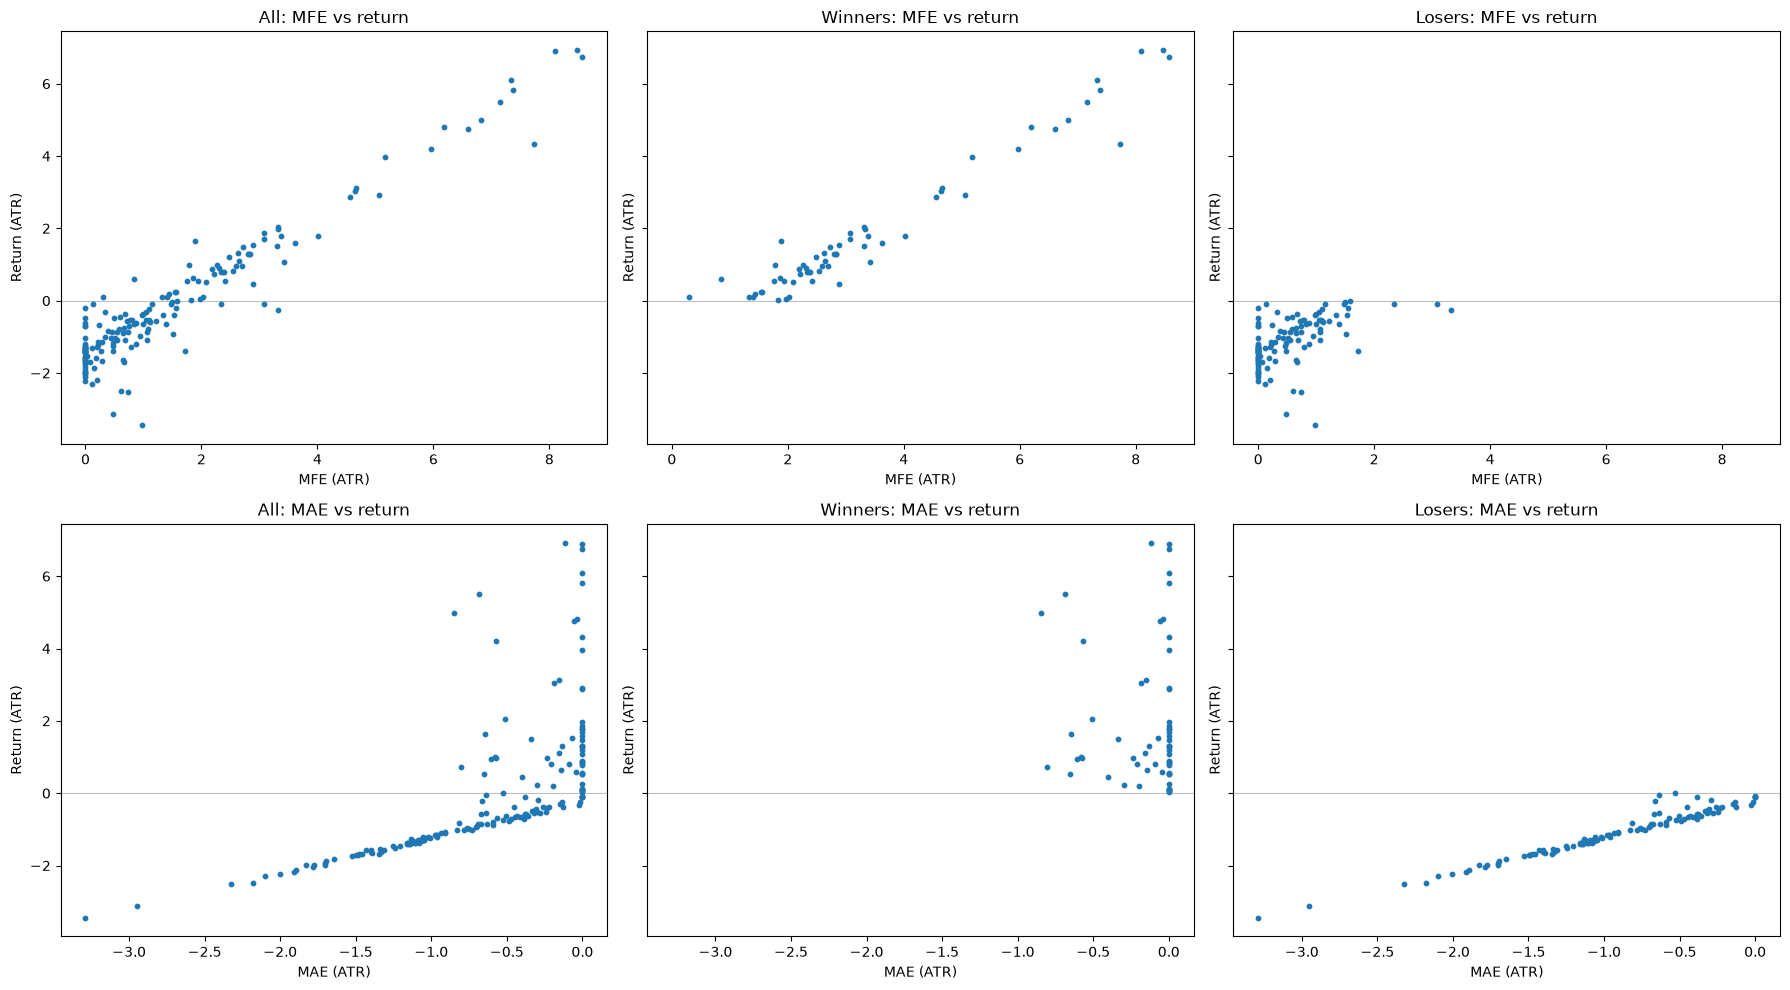

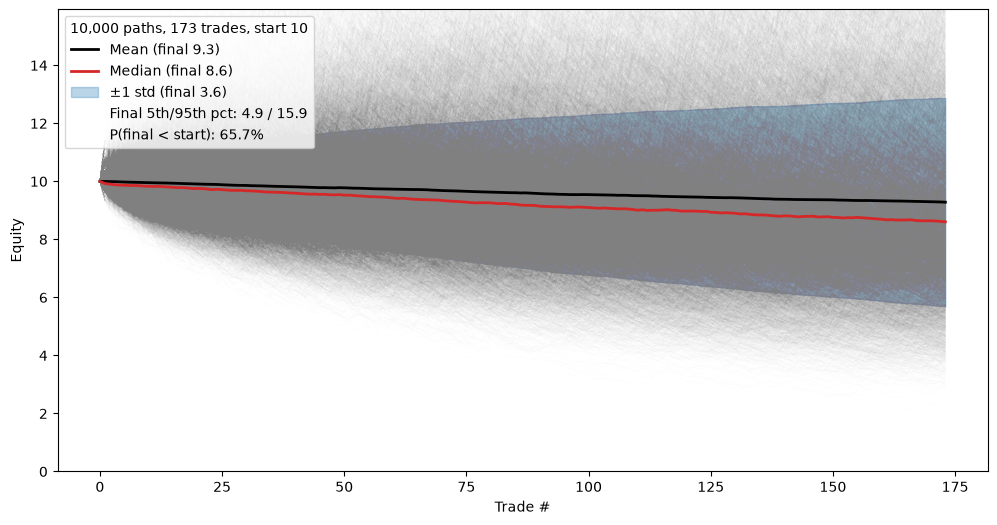

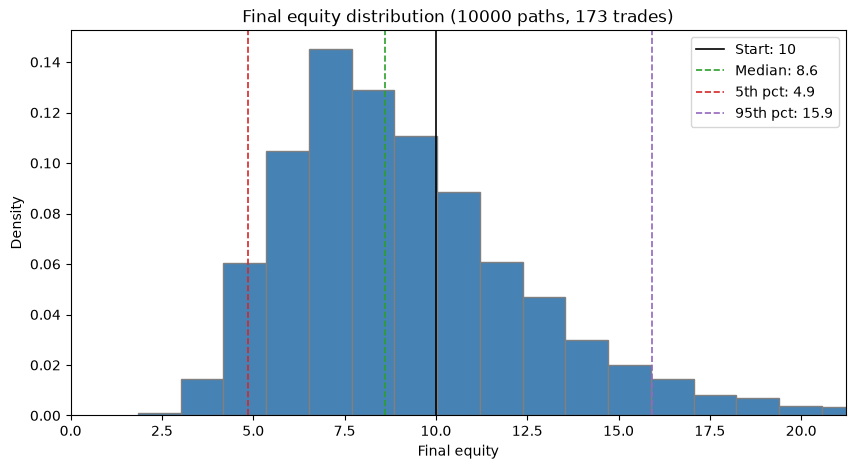

P(loss): 65.7%


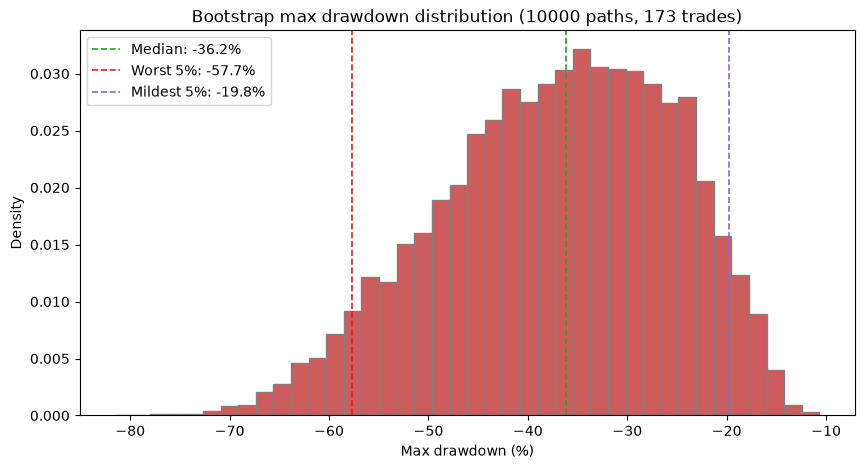

P(maxDD worse than -20%): 94.7%
MaxDD -25.7% on 2026-01-20 | Longest underwater 624d | Median episode 12d | Time underwater 94% | Currently 624d under


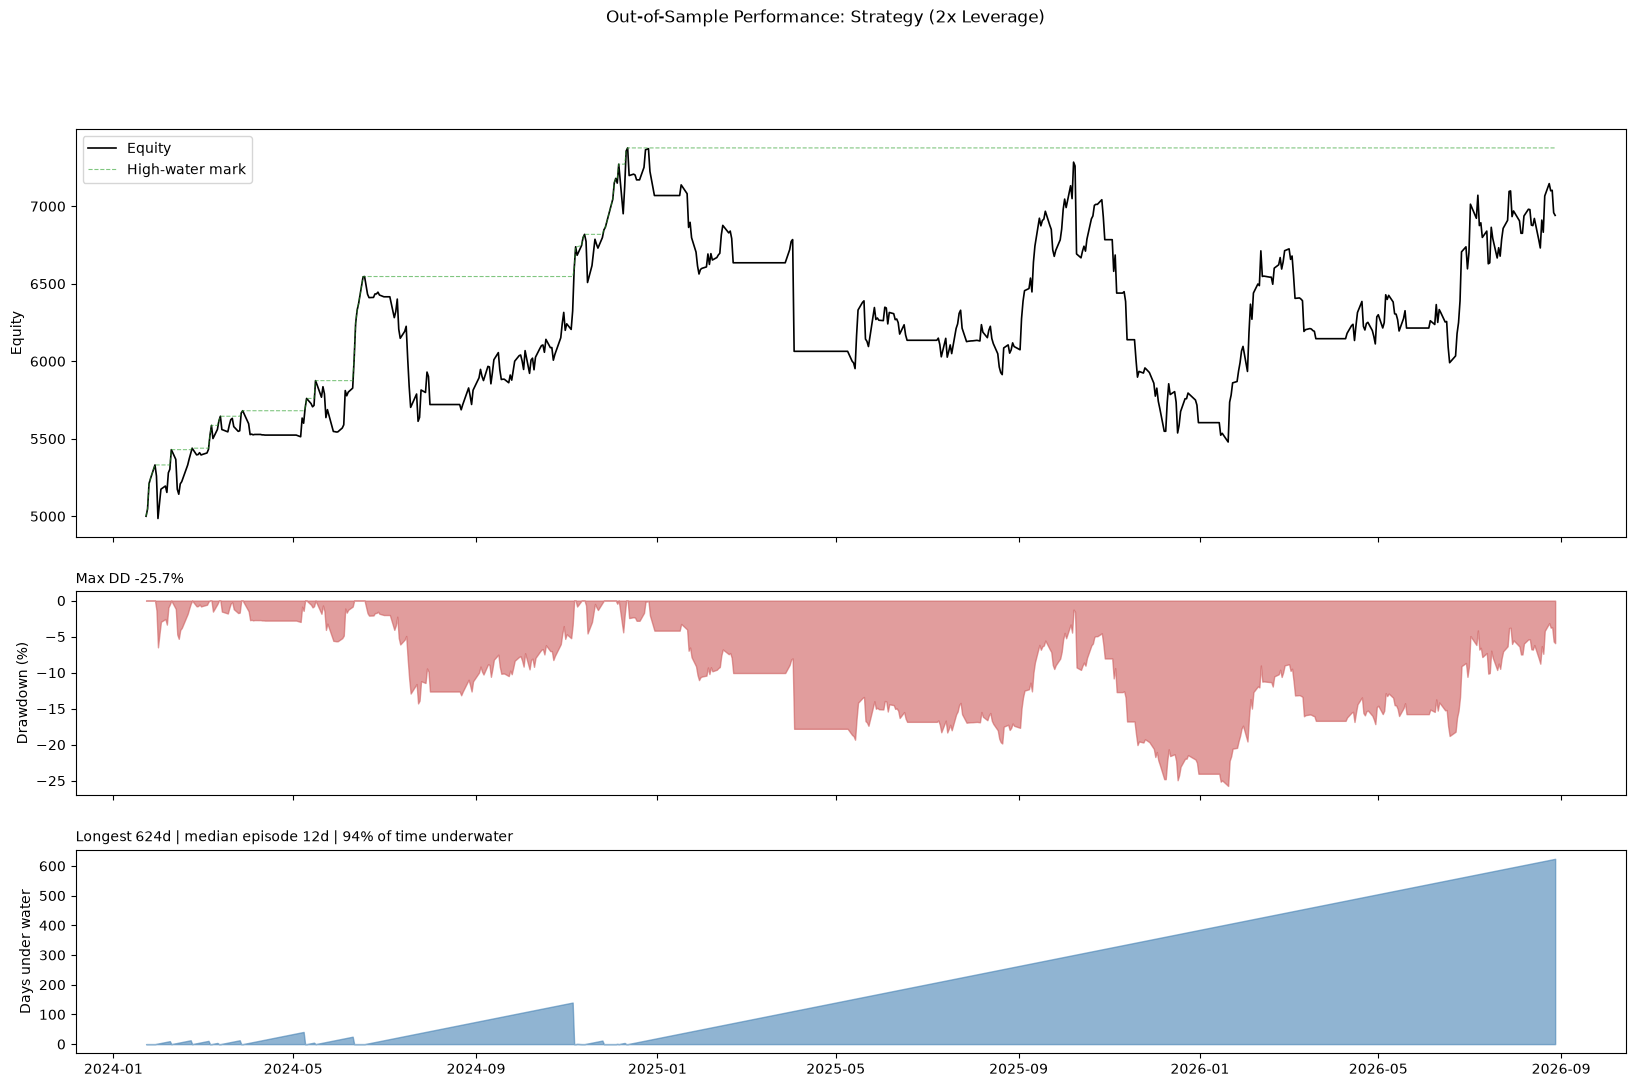

Total return (%)             38.82
CAGR (%)                     13.47
Ann. vol (%)                 22.54
Sharpe                        0.68
Sortino                       0.94
Max DD (%)                  -25.72
Calmar                        0.52
Max DD duration (d)         624.00
Longest underwater (d)      624.00
Time underwater (%)          94.49
Signals                     173.00
Trades filled               125.00
Skipped, no capacity (%)     27.75
Win rate (%)                 38.40
Profit factor                 1.41
Payoff (avg W / avg L)        2.26
Expectancy (R)                0.12
Days in market (%)           77.34
Peak leverage (x)             2.00
rho = 0.32932234327003157
S_i = 1.2810181627204613
rho*S_p = 0.2226248164918011
W_i = 0.8559459980181789
                          Strategy     SPY     Mix
Ann. vol (%)                 22.54   15.80   16.21
CAGR (%)                     13.47   20.84   17.47
Calmar                        0.52    1.11    1.00
Days in market (%)        

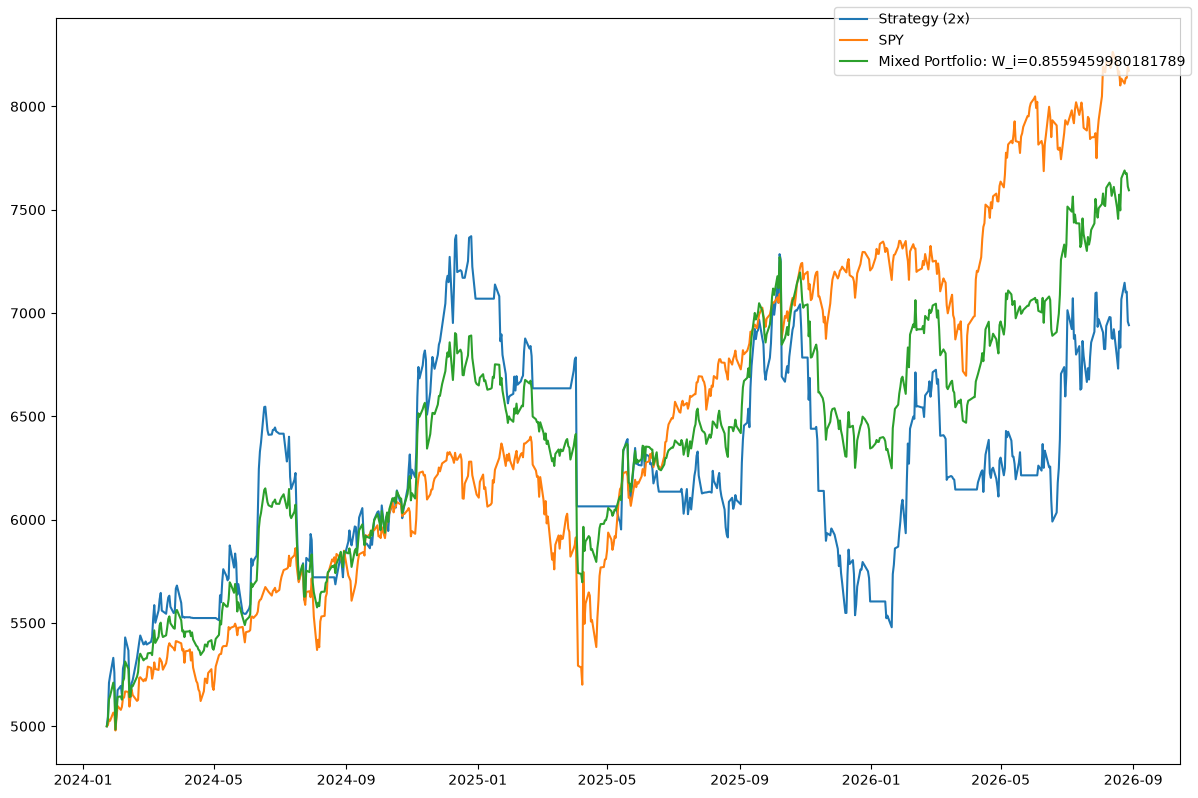

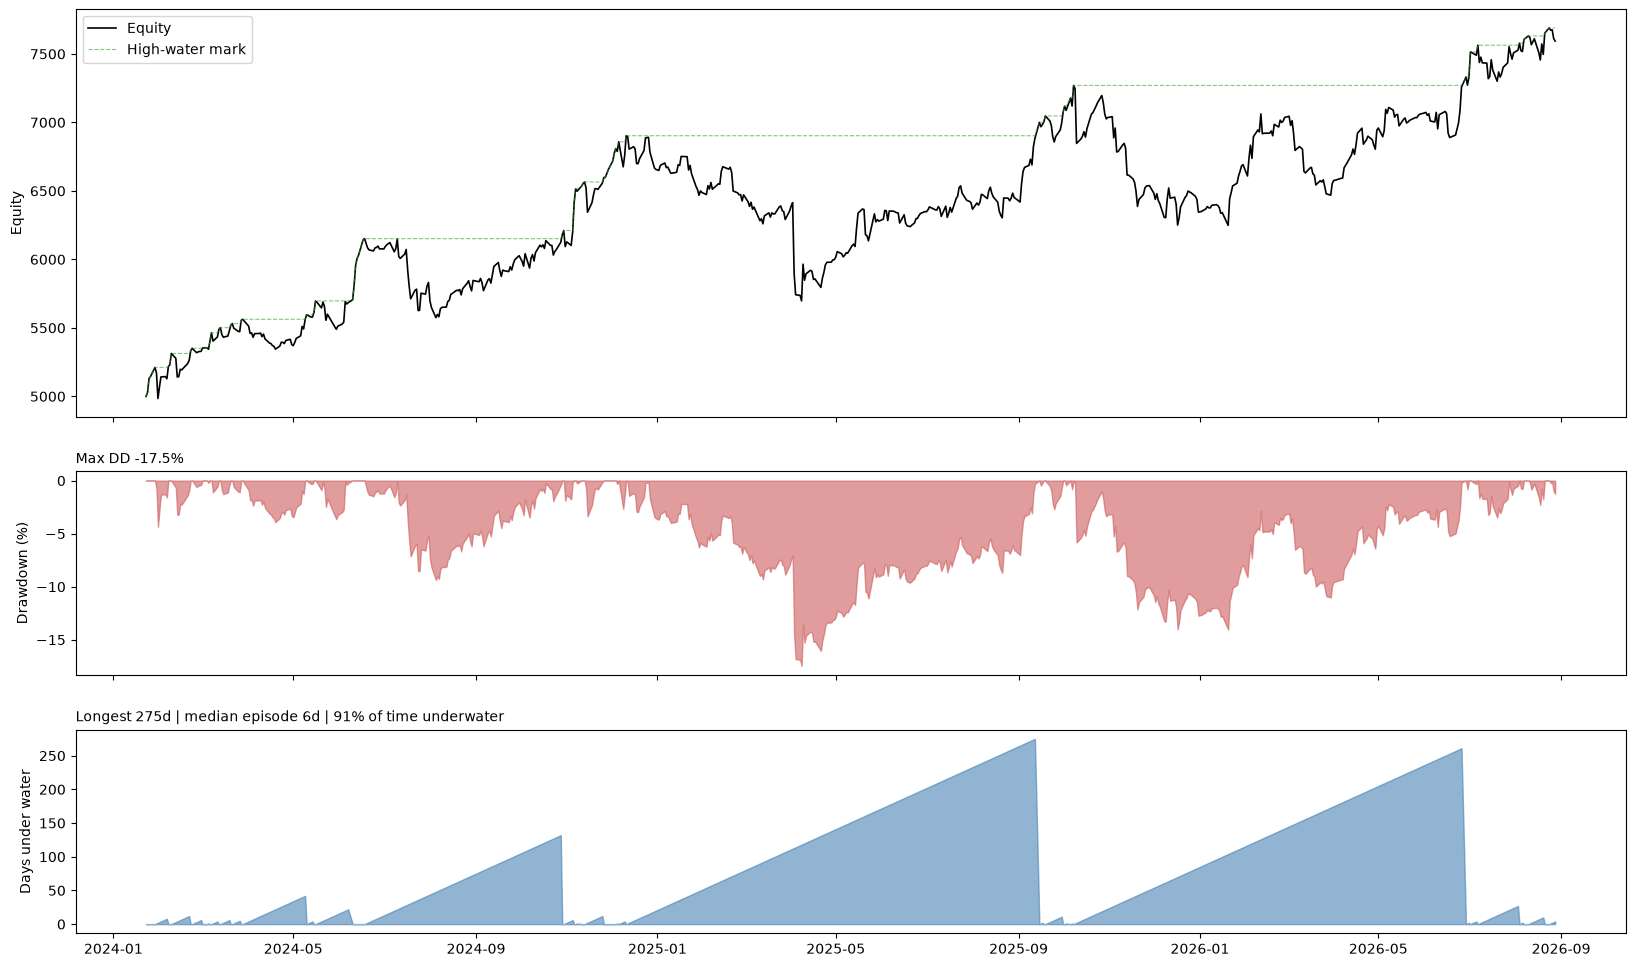

In [38]:
df = test_data
trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = f'Out-of-Sample Performance: Strategy ({MAX_LEVERAGE}x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)

# HEATMAP SPIKE (FULL)

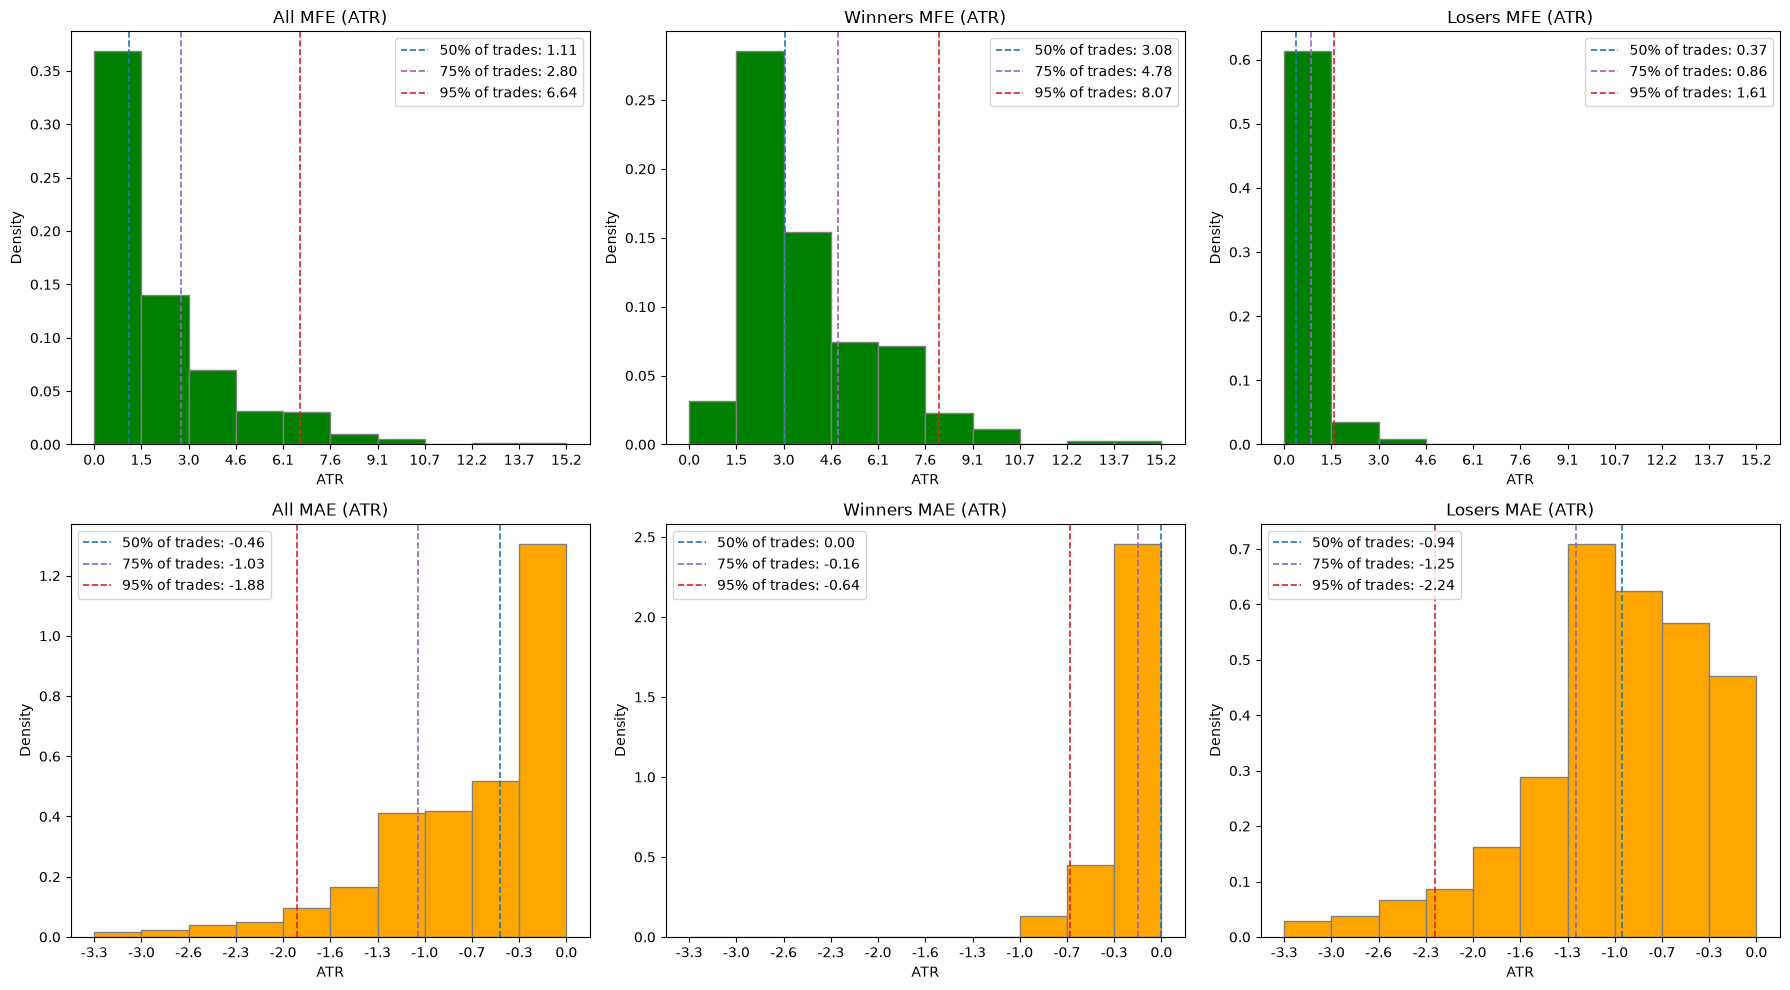

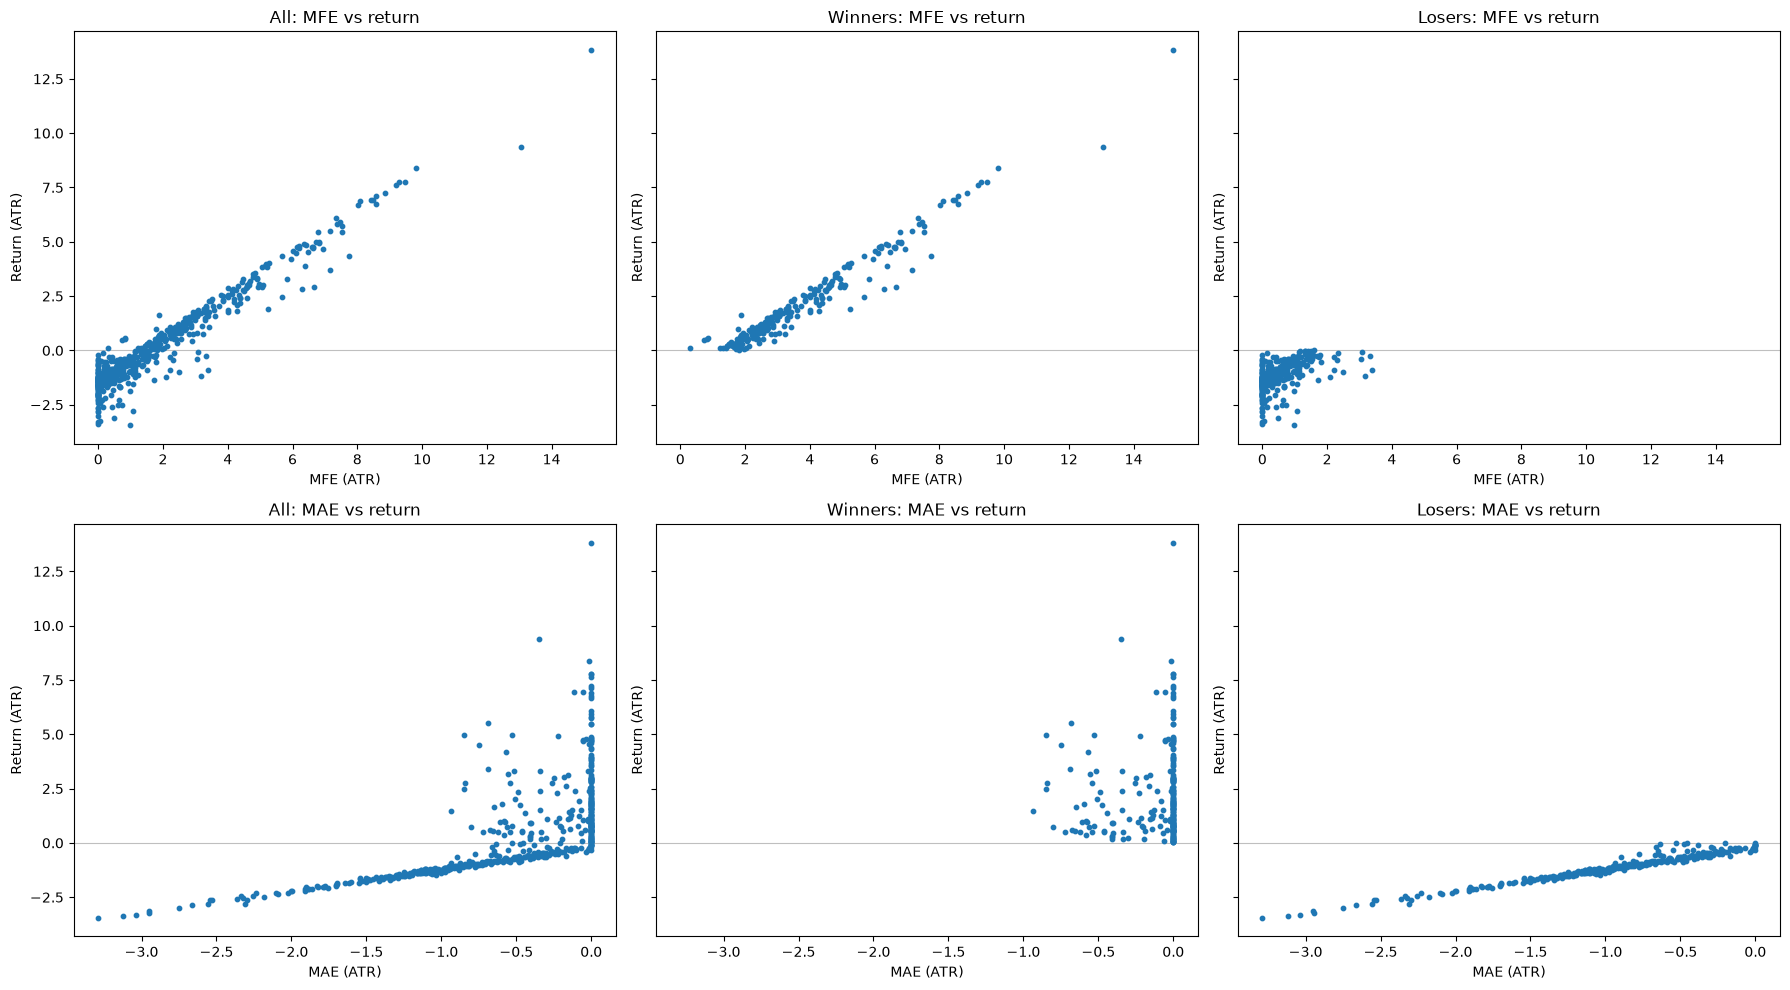

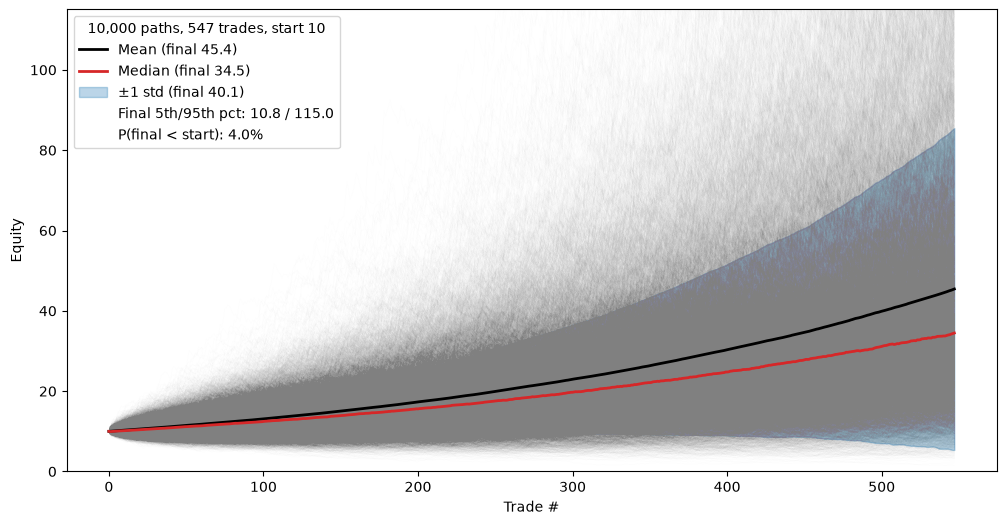

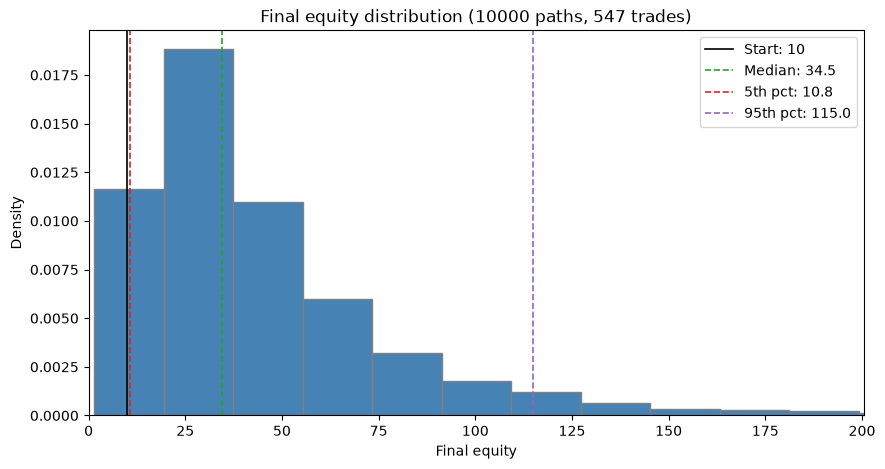

P(loss): 4.0%


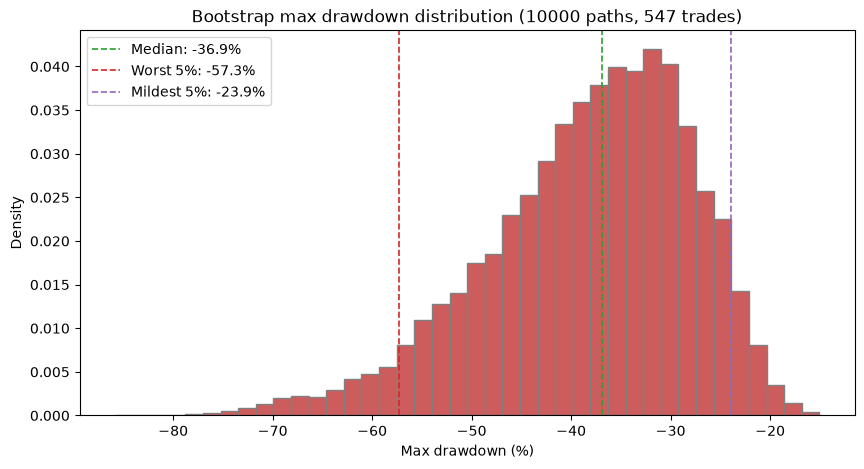

P(maxDD worse than -20%): 99.2%
MaxDD -26.6% on 2020-06-24 | Longest underwater 624d | Median episode 6d | Time underwater 94% | Currently 624d under


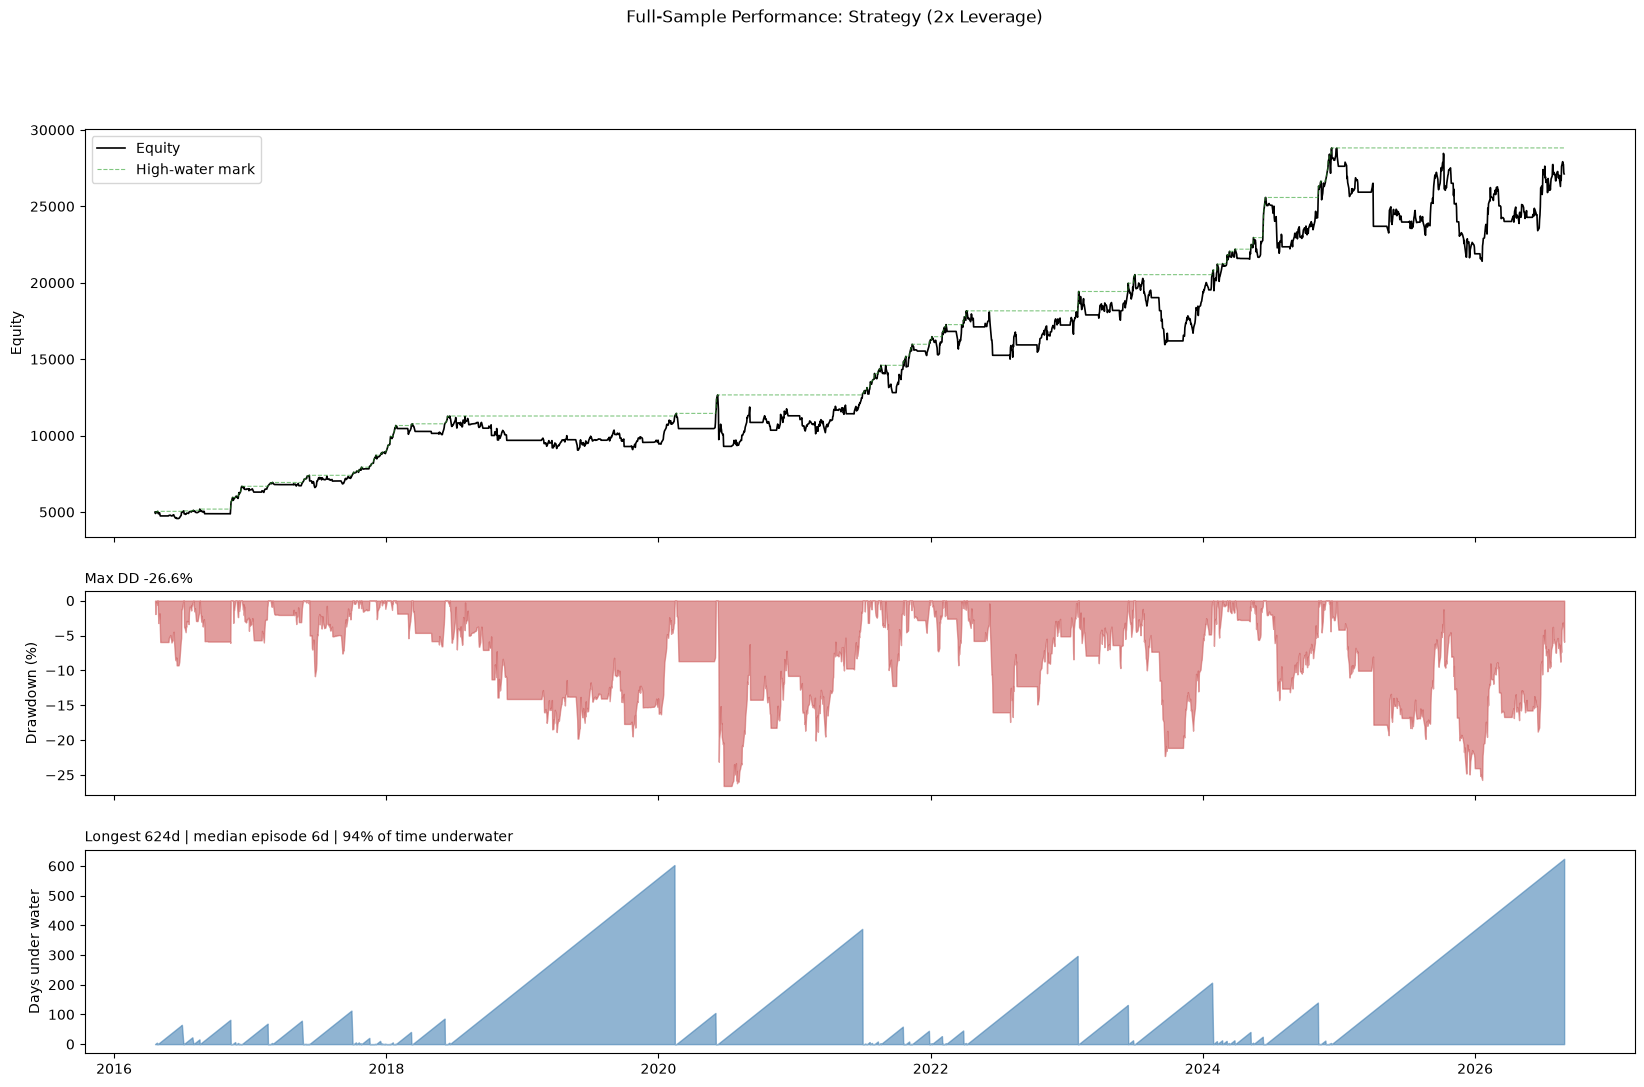

Total return (%)            442.39
CAGR (%)                     17.74
Ann. vol (%)                 21.63
Sharpe                        0.87
Sortino                       1.21
Max DD (%)                  -26.58
Calmar                        0.67
Max DD duration (d)         389.00
Longest underwater (d)      624.00
Time underwater (%)          93.63
Signals                     547.00
Trades filled               424.00
Skipped, no capacity (%)     22.49
Win rate (%)                 44.10
Profit factor                 1.51
Payoff (avg W / avg L)        1.91
Expectancy (R)                0.18
Days in market (%)           68.83
Peak leverage (x)             2.00
rho = 0.32747112027701814
S_i = 0.8860207127466606
rho*S_p = 0.2835703347548842
W_i = 0.5600912284282137
                          Strategy     SPY     Mix
Ann. vol (%)                 21.63   17.78   16.38
CAGR (%)                     17.74   15.18   17.36
Calmar                        0.67    0.45    0.86
Days in market (%)        

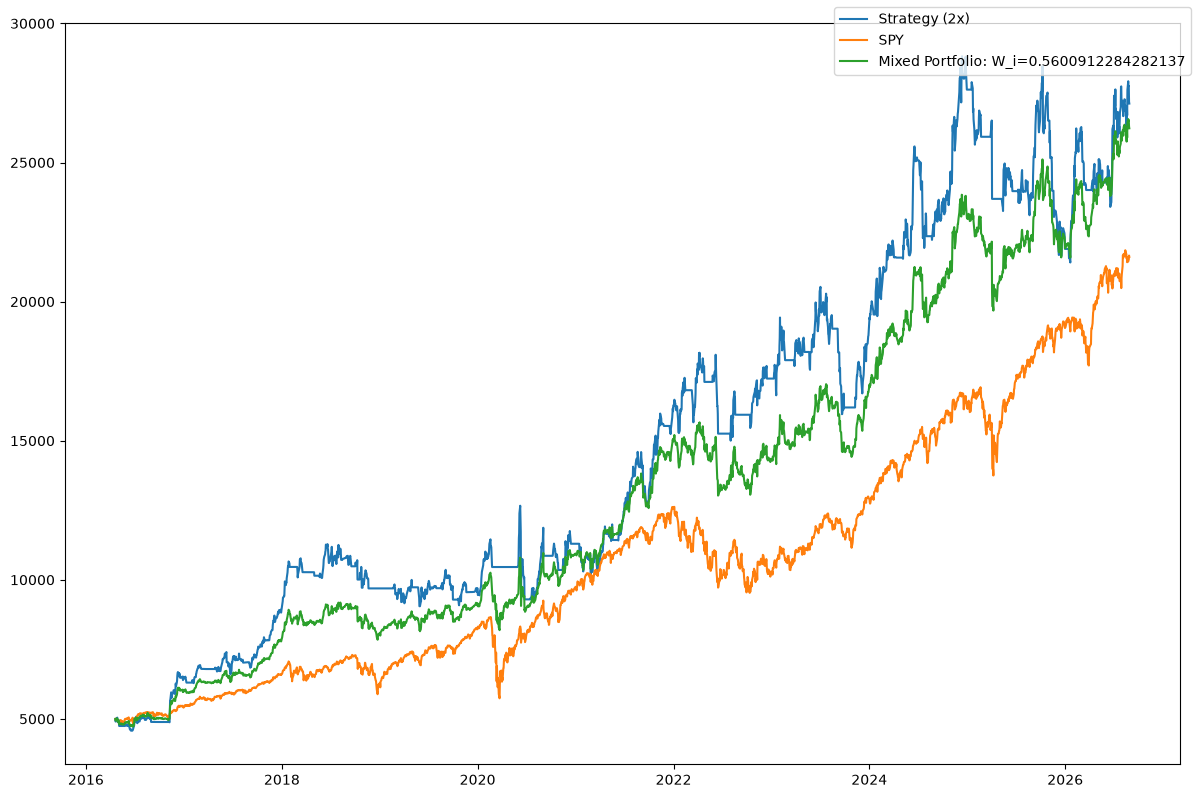

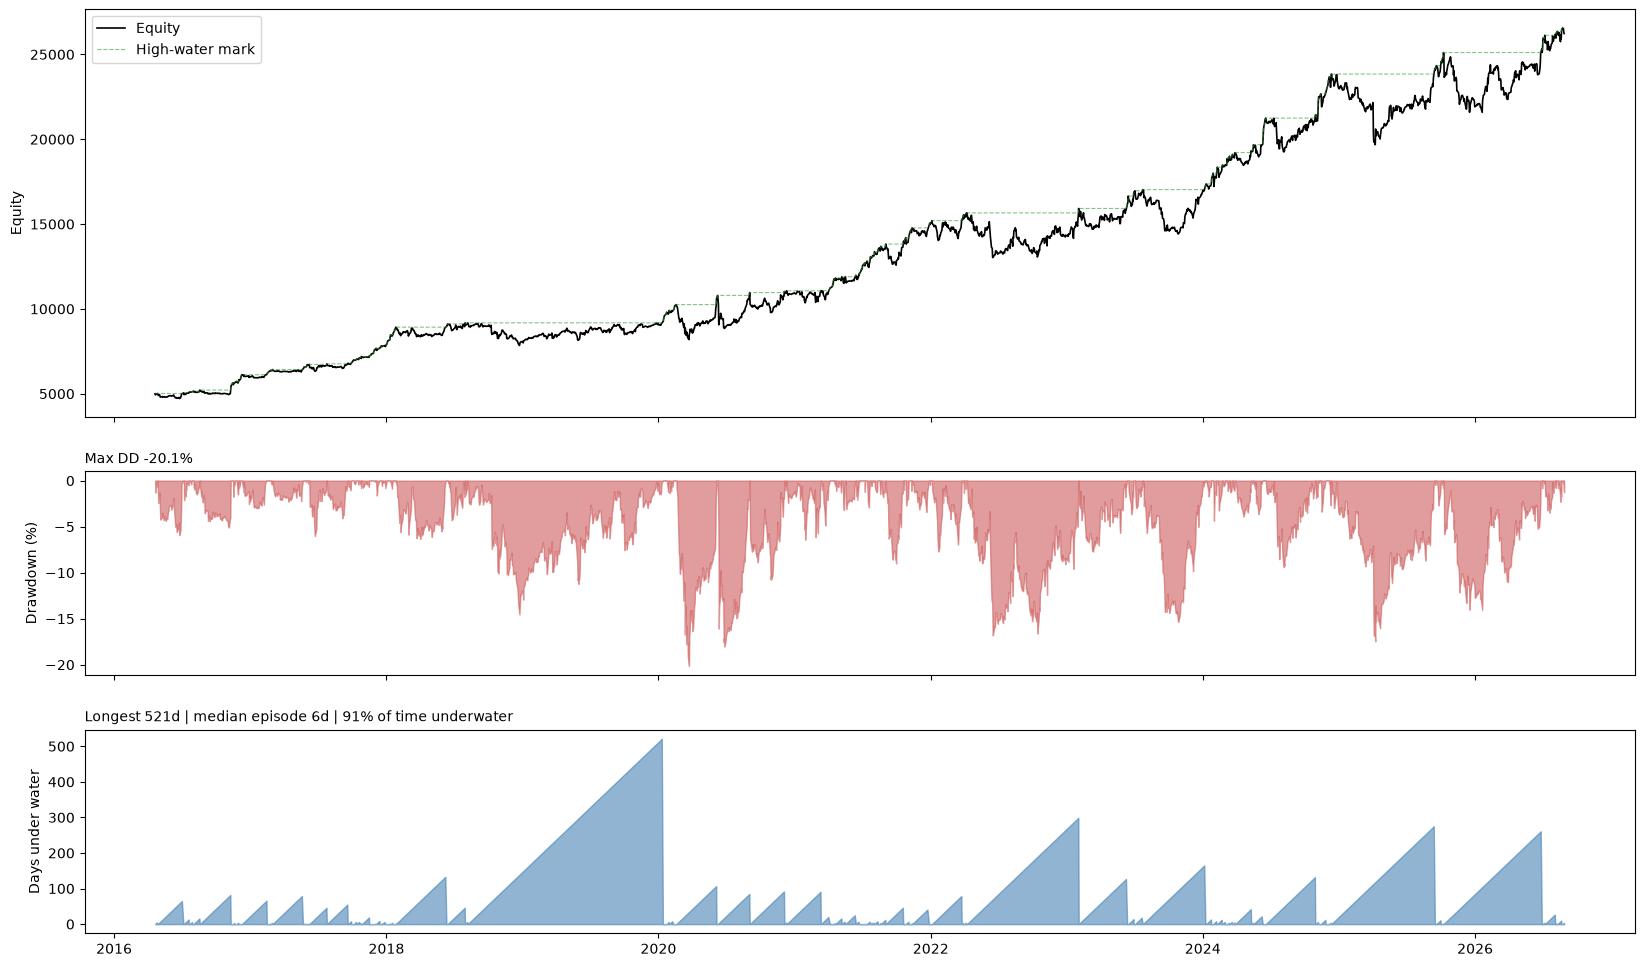

In [39]:
df = all_data
trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = f'Full-Sample Performance: Strategy ({MAX_LEVERAGE}x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)

# NO HEATMAP SPIKE (TRAIN)

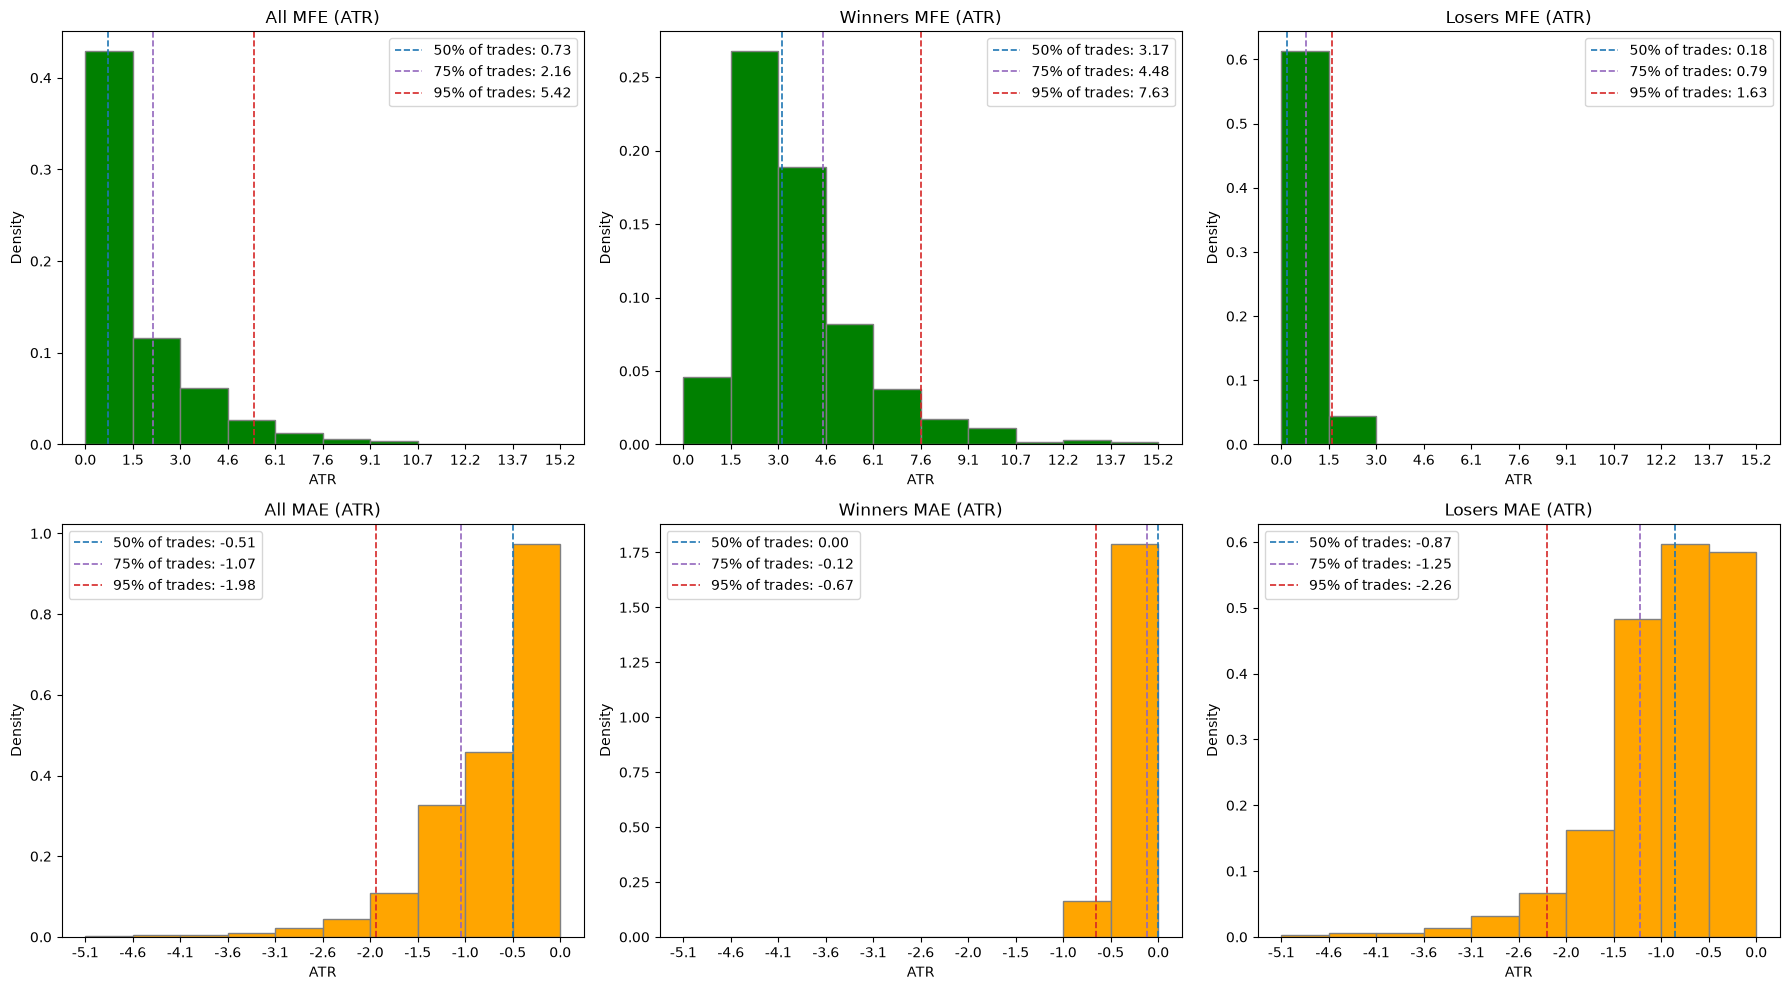

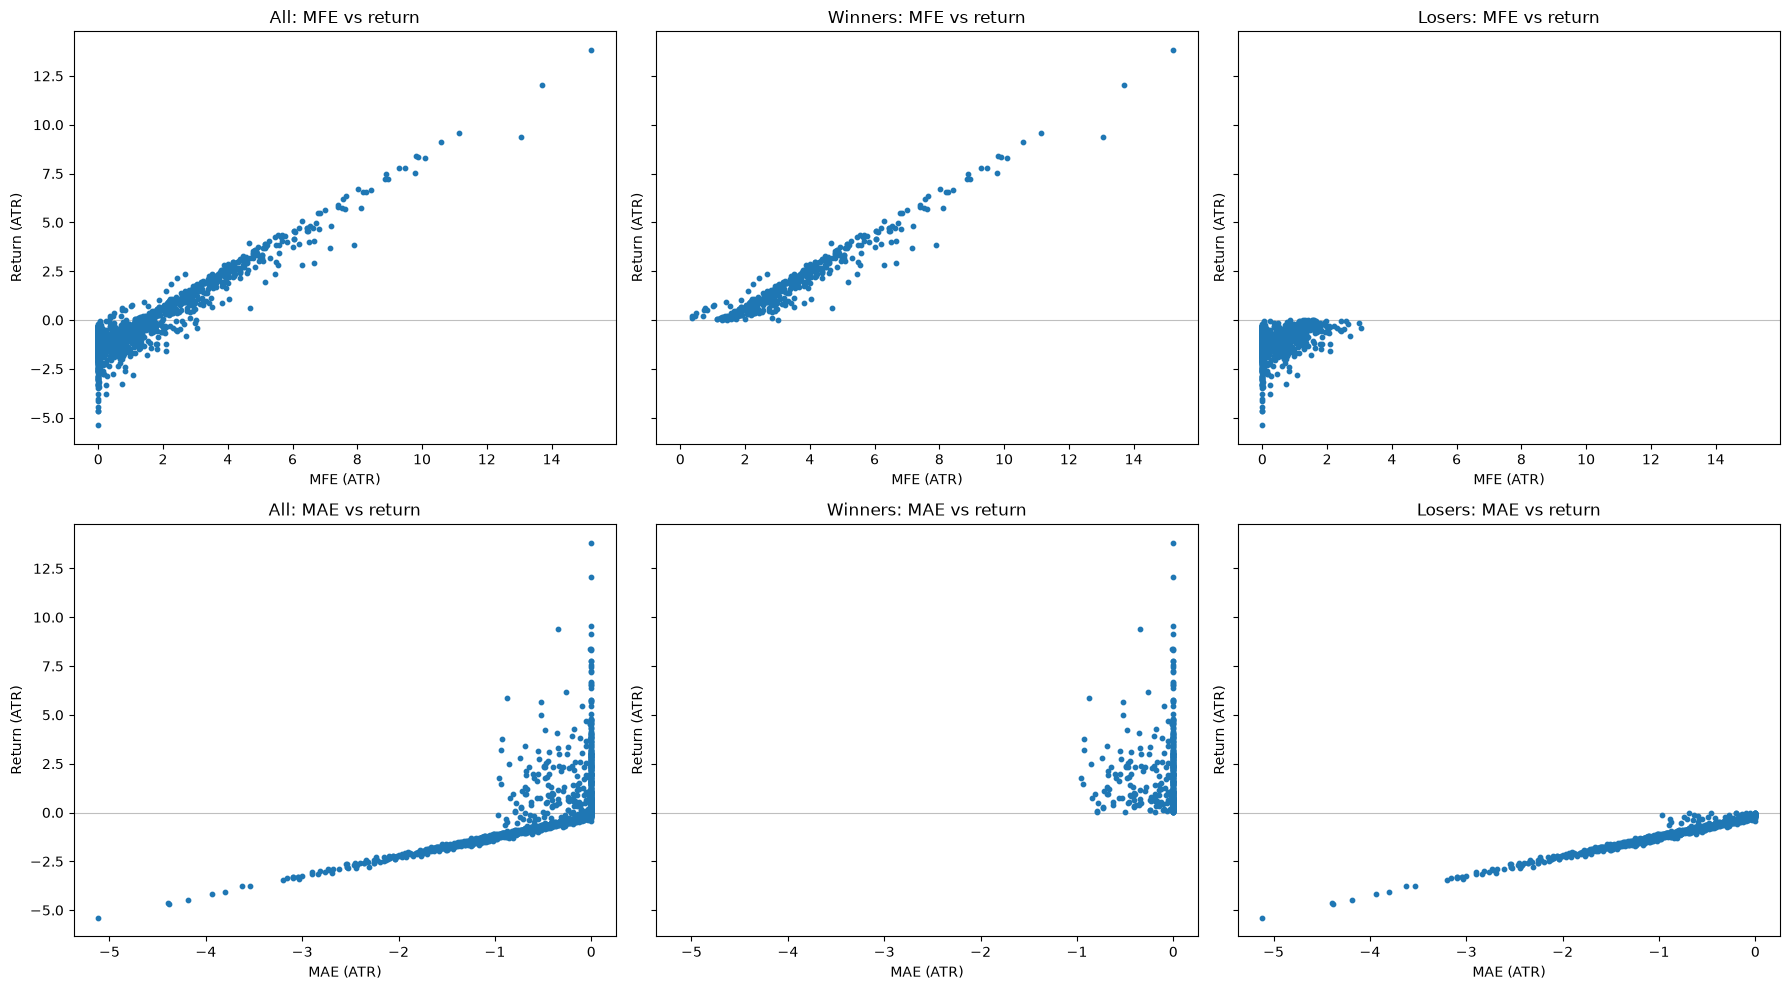

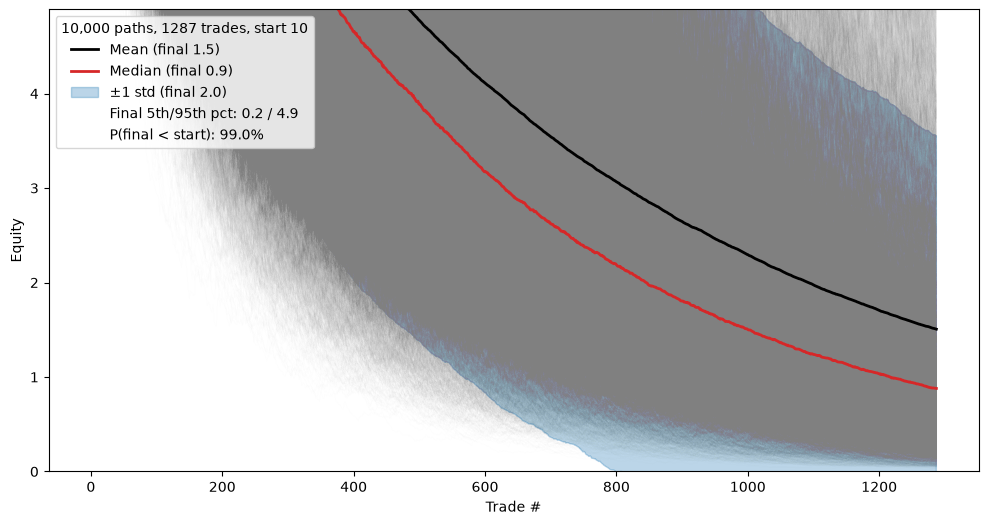

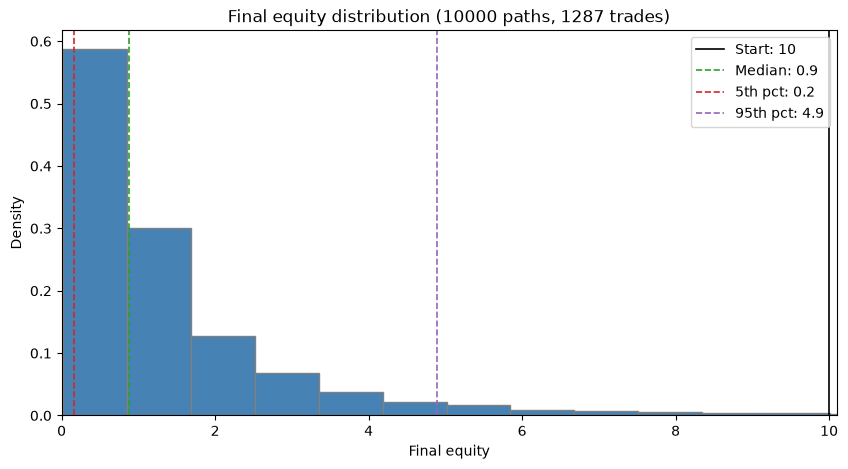

P(loss): 99.0%


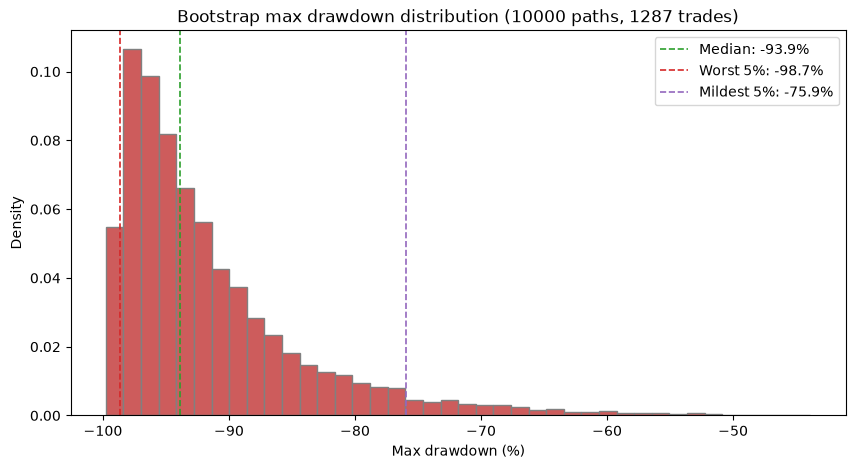

P(maxDD worse than -20%): 100.0%
MaxDD -78.1% on 2023-03-09 | Longest underwater 2163d | Median episode 4d | Time underwater 98% | Currently 2163d under


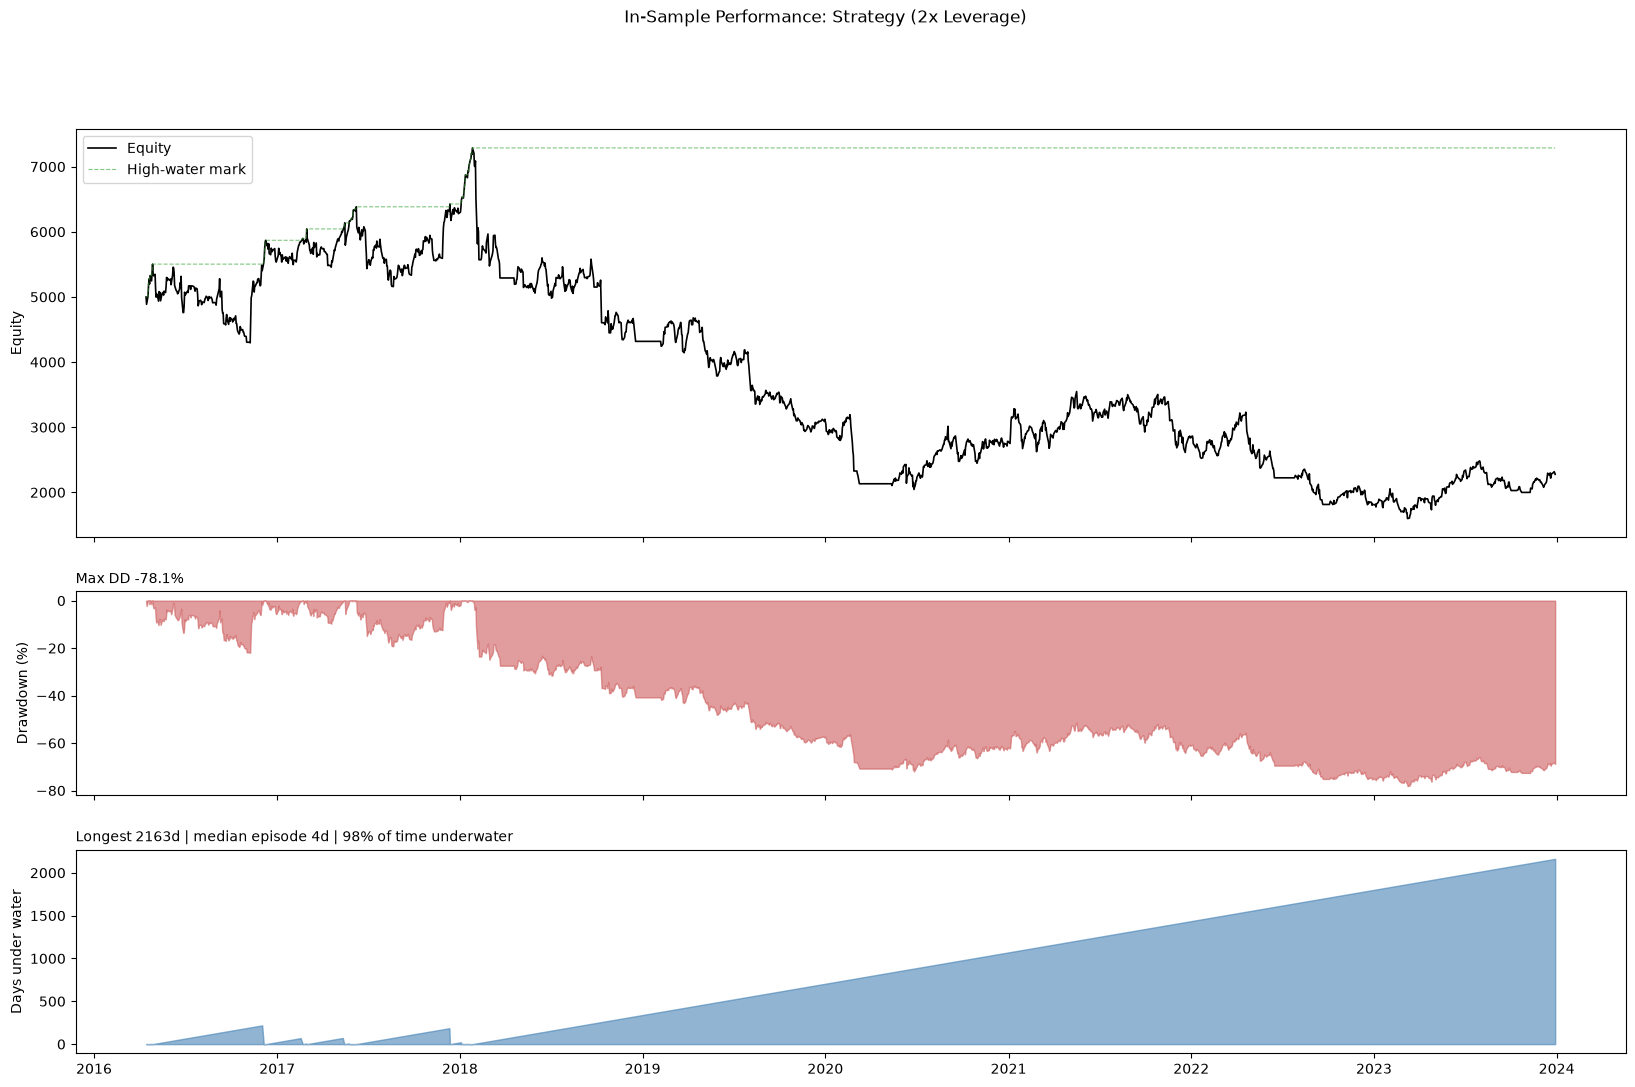

Total return (%)             -54.47
CAGR (%)                      -9.70
Ann. vol (%)                  30.45
Sharpe                        -0.18
Sortino                       -0.24
Max DD (%)                   -78.06
Calmar                        -0.12
Max DD duration (d)         2163.00
Longest underwater (d)      2163.00
Time underwater (%)           98.15
Signals                     1287.00
Trades filled                801.00
Skipped, no capacity (%)      37.76
Win rate (%)                  33.71
Profit factor                  0.85
Payoff (avg W / avg L)         1.68
Expectancy (R)                -0.02
Days in market (%)            90.63
Peak leverage (x)              2.00
rho = 0.5526063230687146
S_i = 0.7707101548907692
rho*S_p = -0.10035618999796392
W_i = 1.730045405899395
                          Strategy     SPY     Mix
Ann. vol (%)                 30.45   18.43   18.43
CAGR (%)                     -9.70   13.30   13.30
Calmar                       -0.12    0.39    0.39
Days in

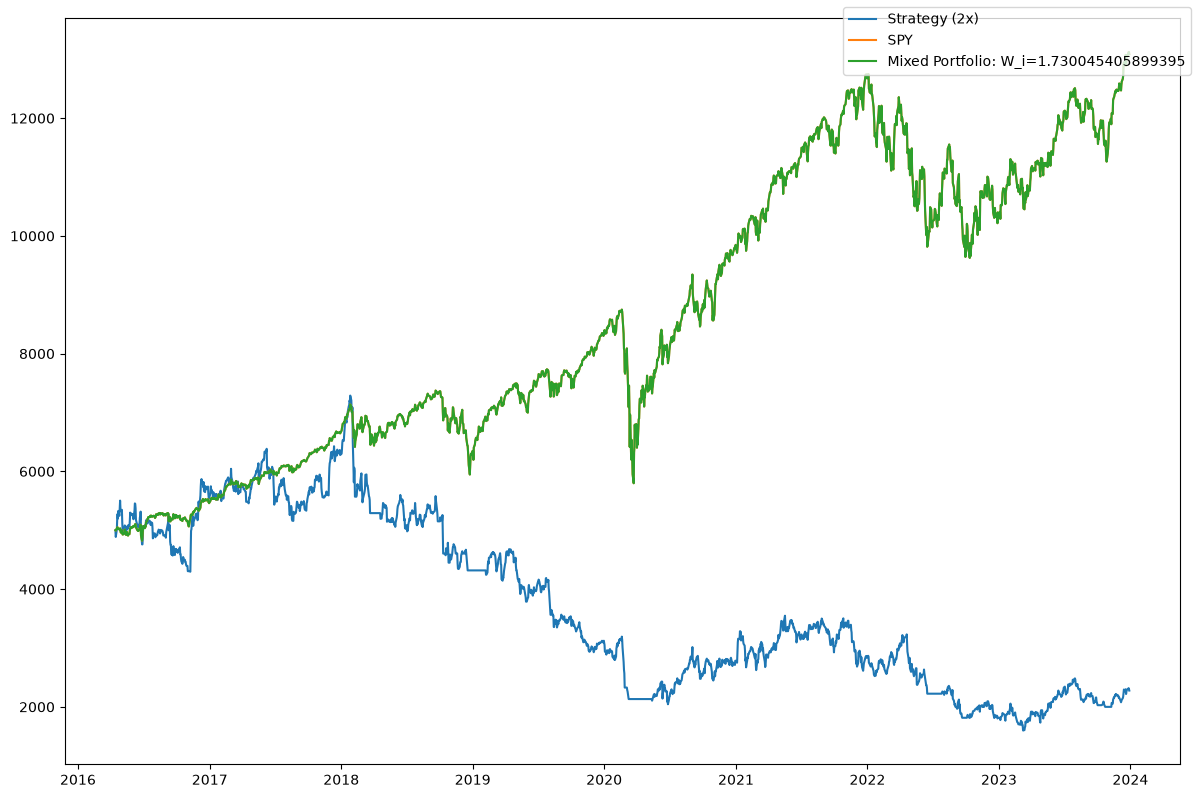

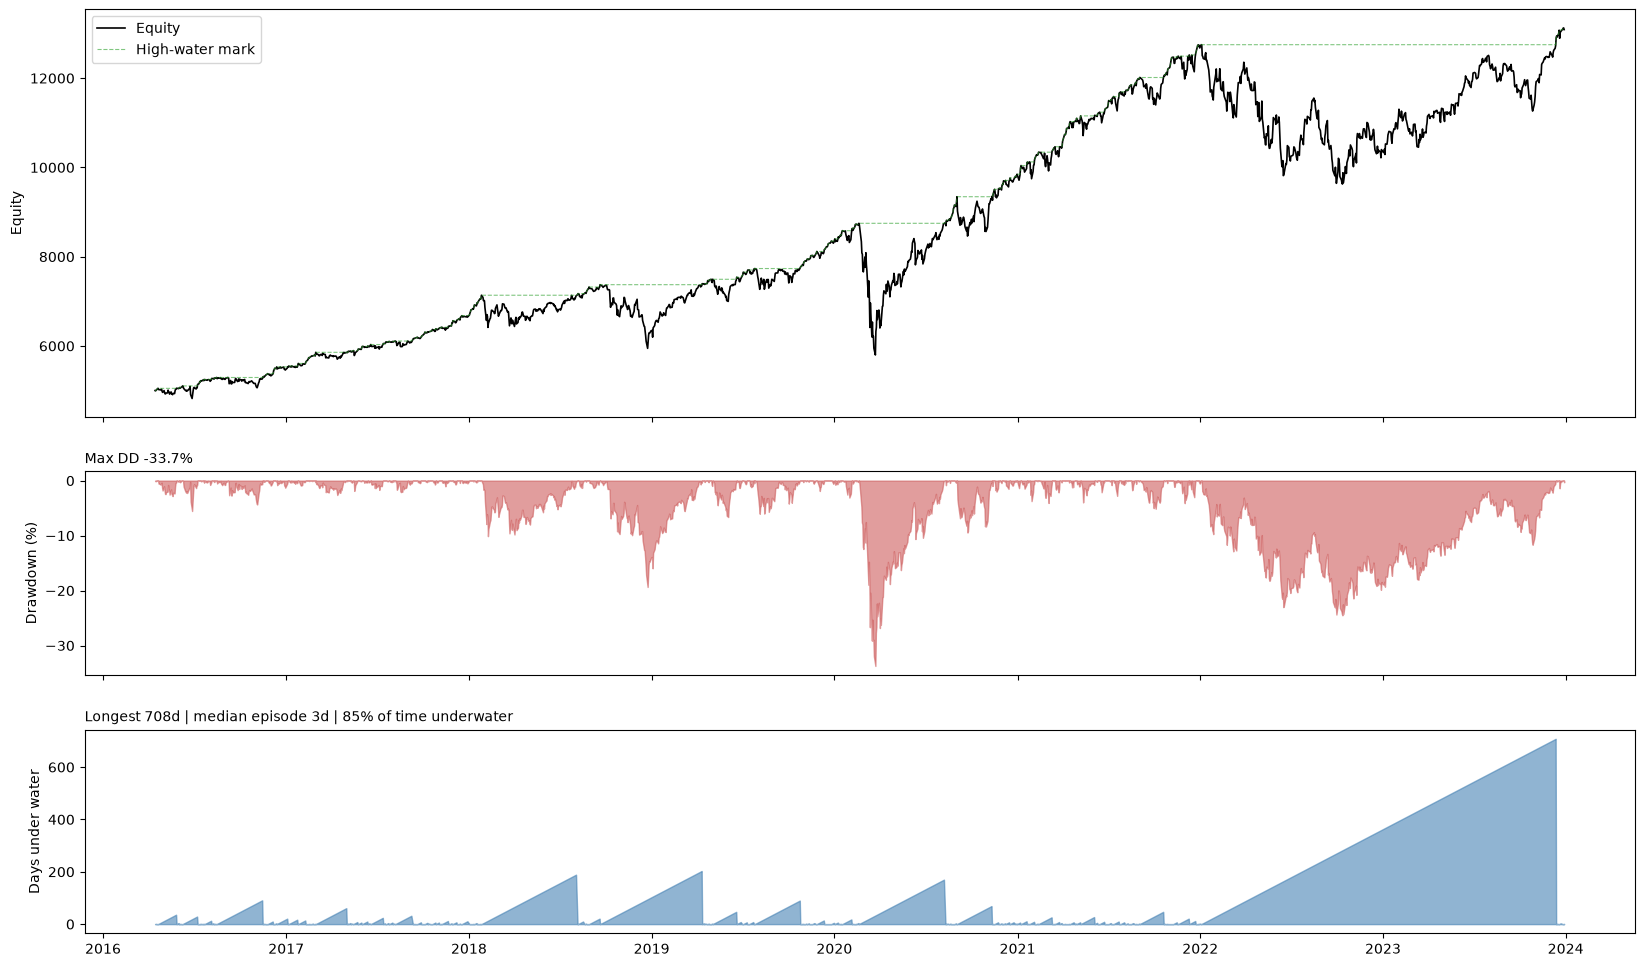

In [40]:
df = train_data

# Conditions: (d, t) for entry, (d, t, i) for exit, where t = current bar, i = entry bar
entry_fn = lambda d, t: d['Stage2'][t] == 1
exit_fn = lambda d, t, i: (d['Stage'][t] != 2 or d['Close'][t] <= d['Close'][i:t + 1].max() - TRAIL_ATR * d['ATR14'][i]) #Non-Stage 2 and Trailing Stop
# exit_fn = lambda d, t, i: (d['Stage'][t] != 2) #Non-Stage 2 

trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = 'In-Sample Performance: Strategy (2x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

train_W_i = bf.SPY_combo(daily,t,is_train=True)

# NO HEATMAP SPIKE (TEST)

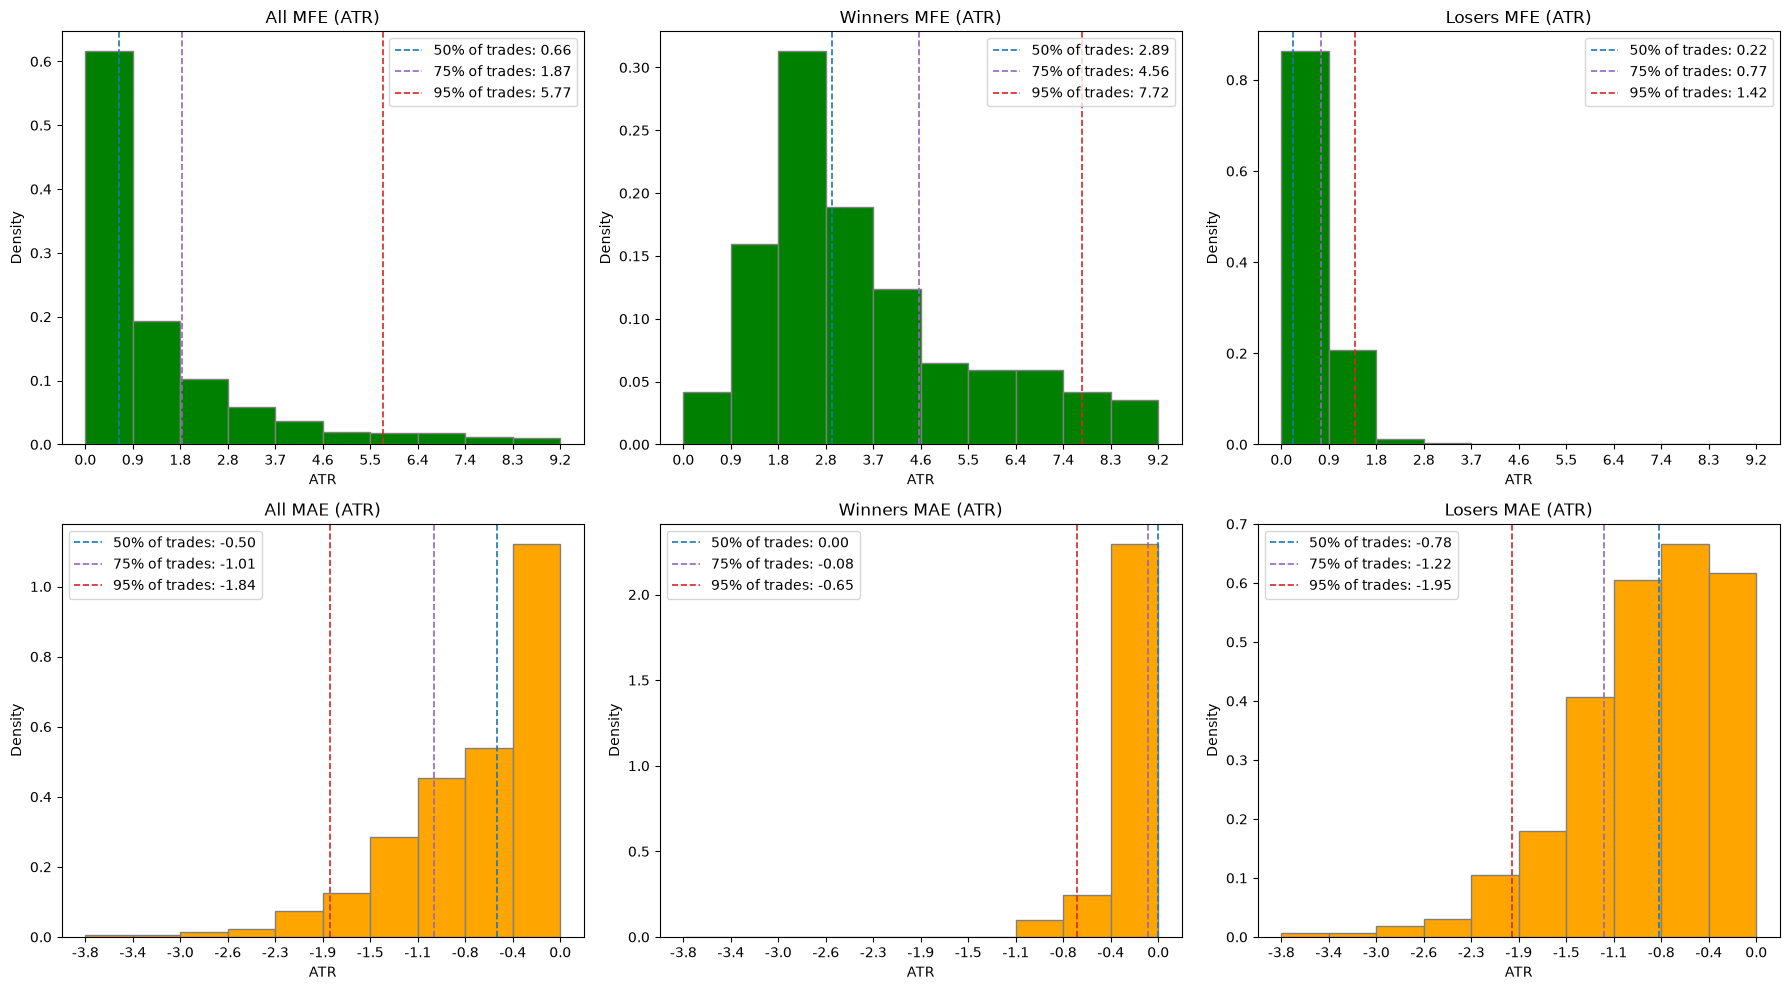

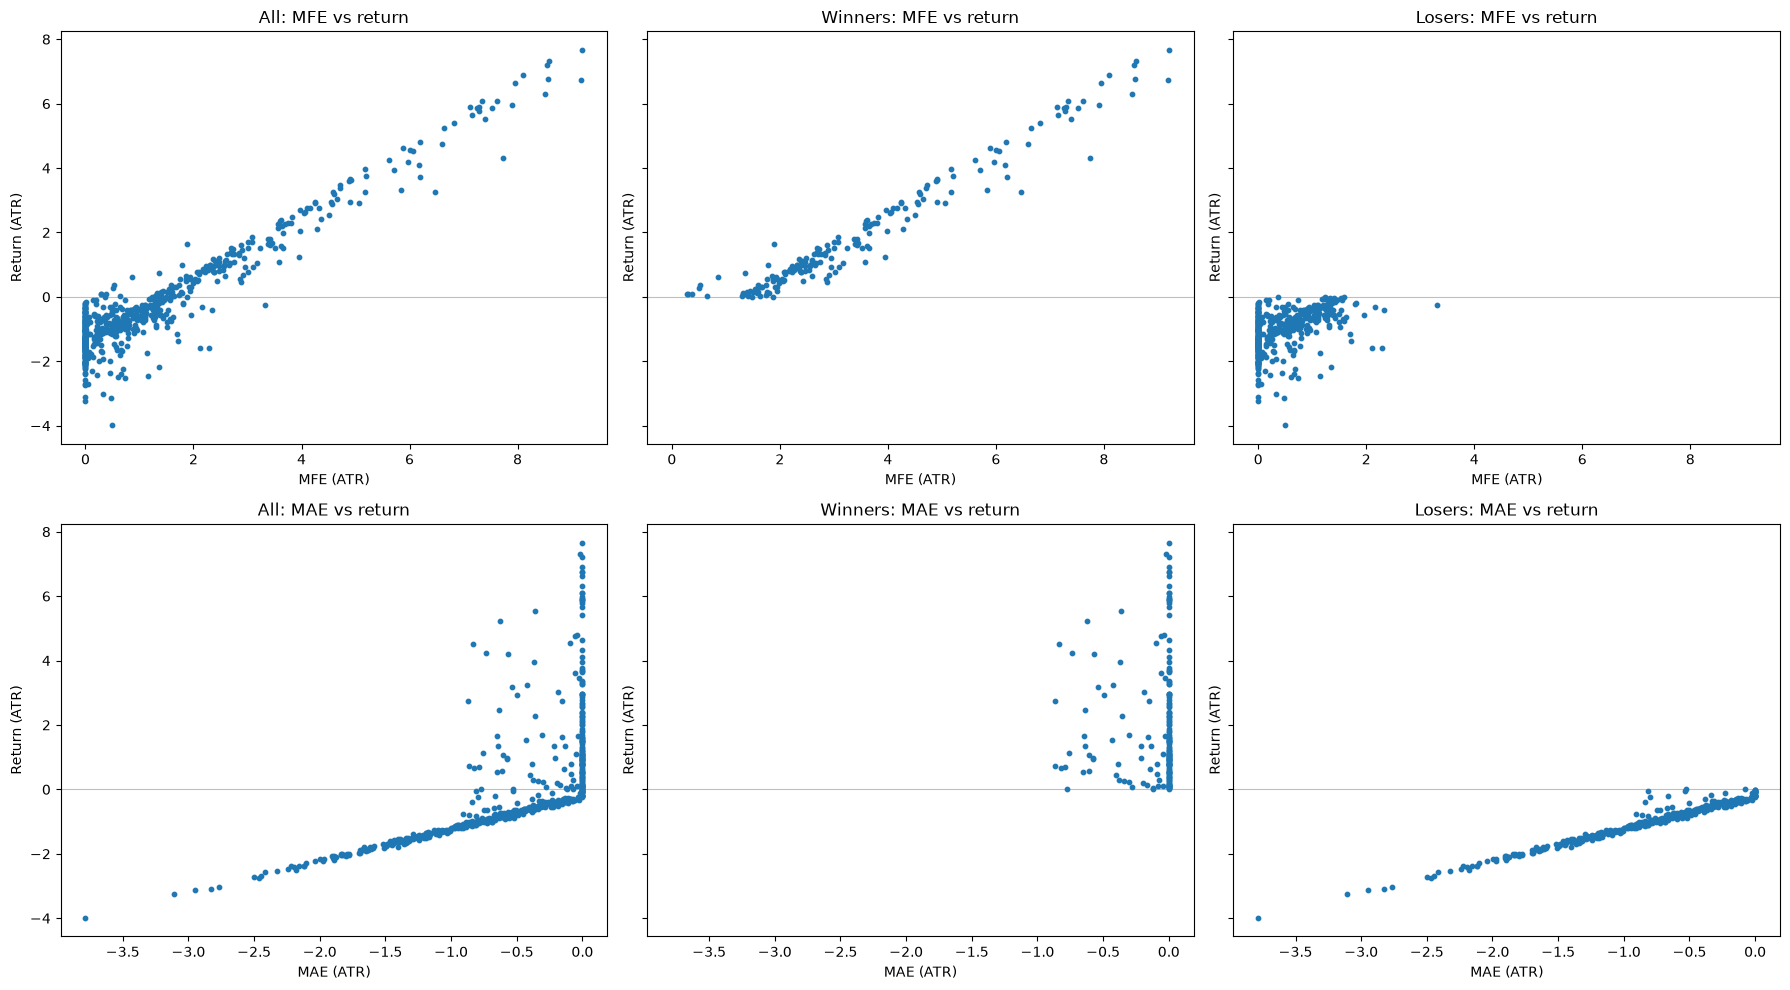

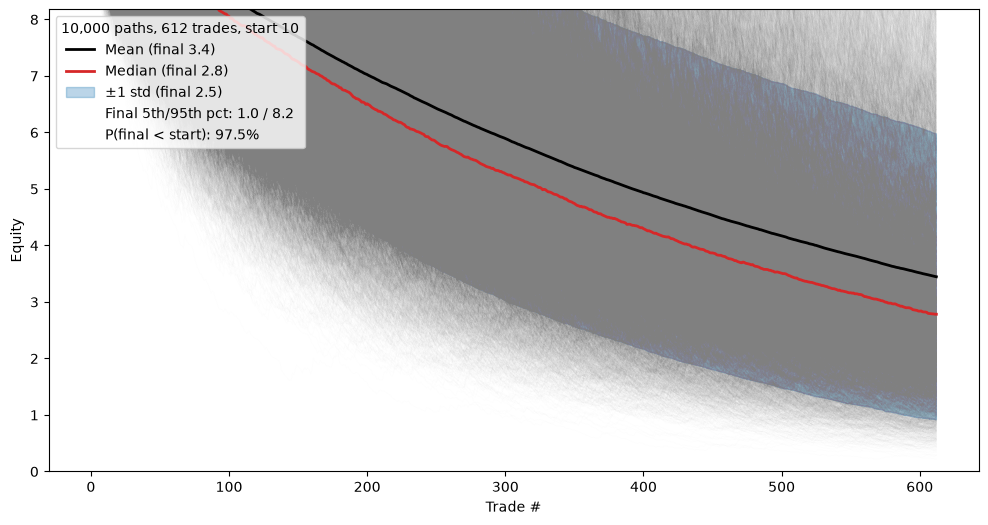

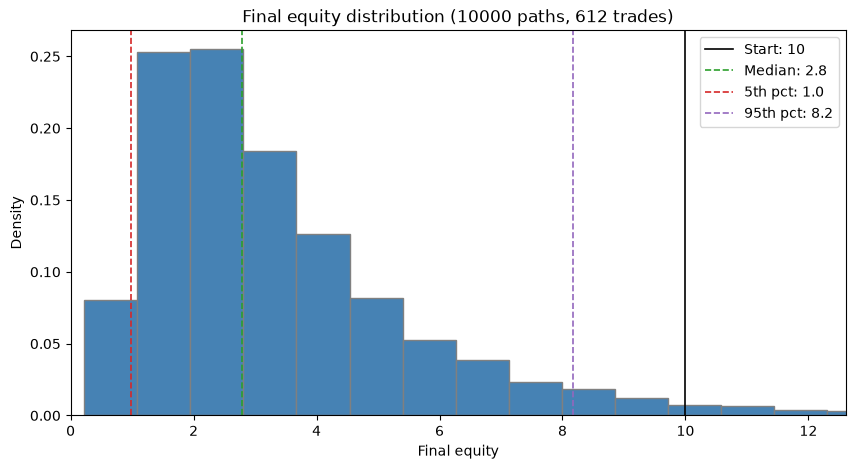

P(loss): 97.5%


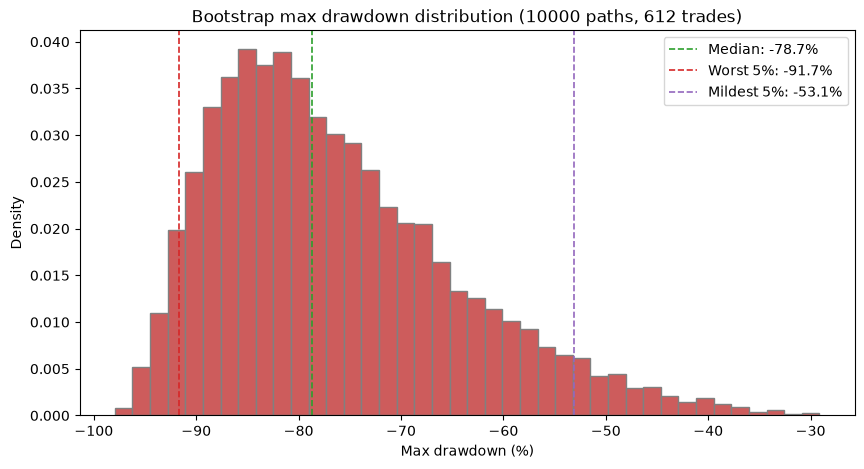

P(maxDD worse than -20%): 100.0%
MaxDD -43.1% on 2025-08-01 | Longest underwater 877d | Median episode 8d | Time underwater 98% | Currently 877d under


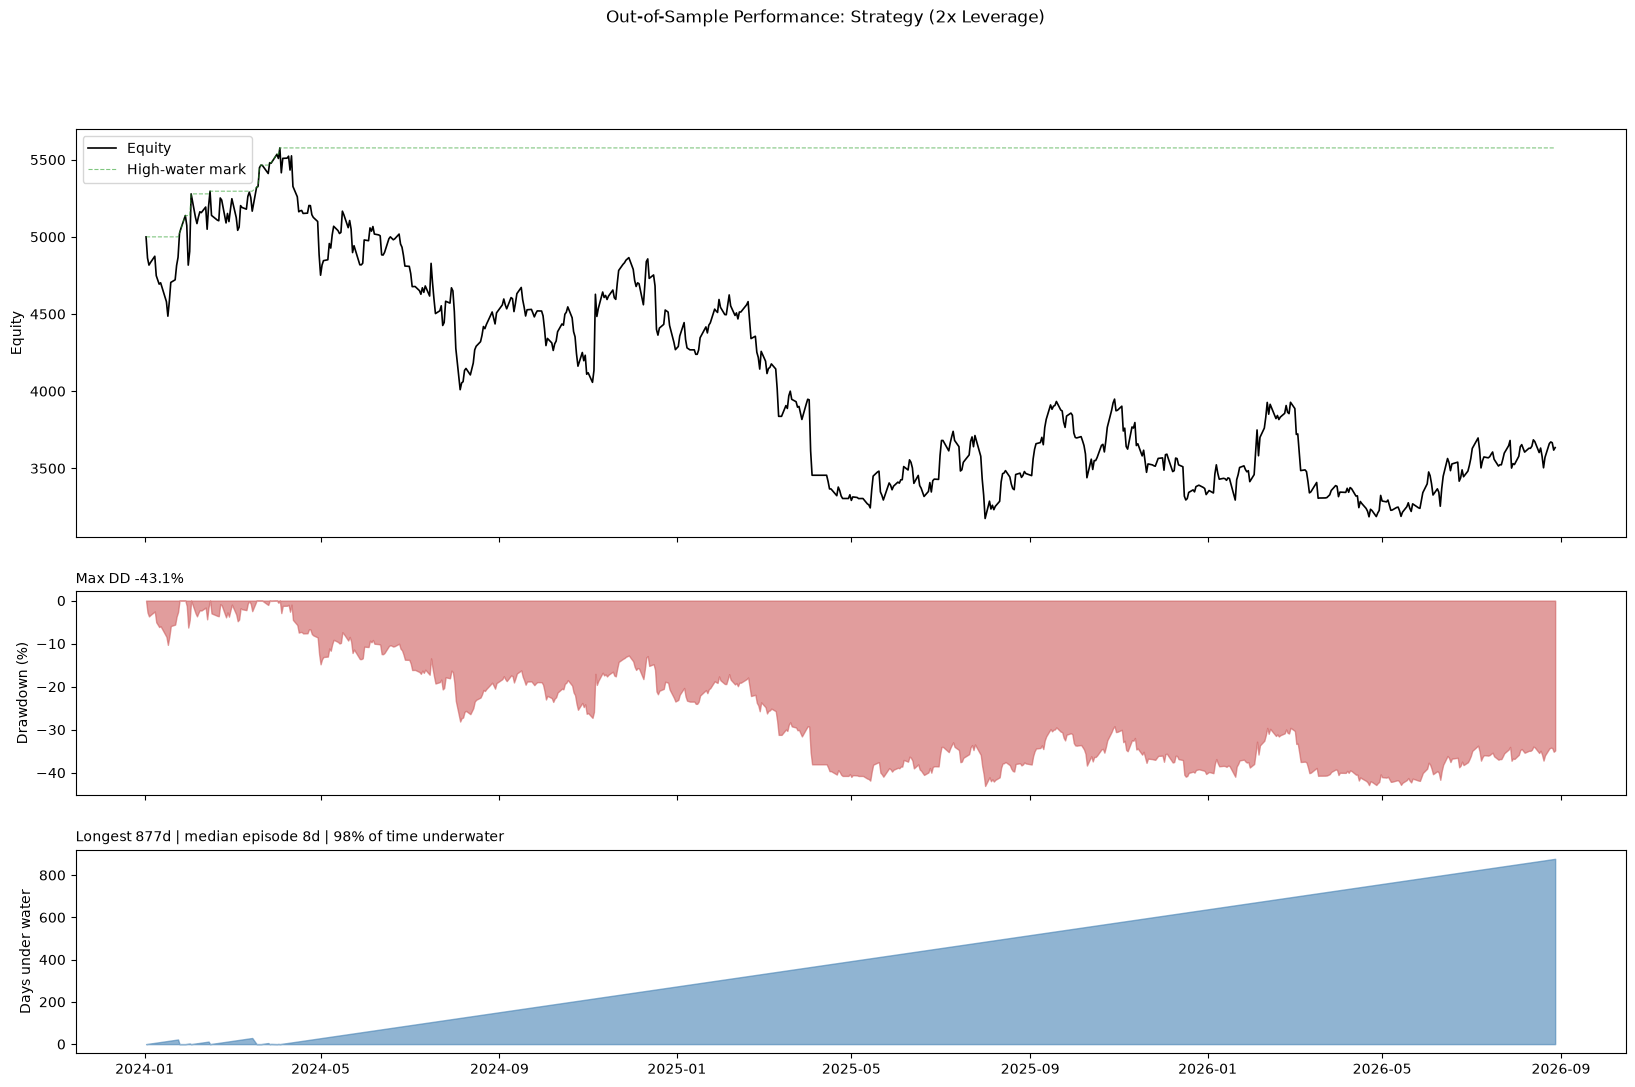

Total return (%)            -27.31
CAGR (%)                    -11.33
Ann. vol (%)                 28.25
Sharpe                       -0.29
Sortino                      -0.39
Max DD (%)                  -43.07
Calmar                       -0.26
Max DD duration (d)         877.00
Longest underwater (d)      877.00
Time underwater (%)          98.05
Signals                     612.00
Trades filled               367.00
Skipped, no capacity (%)     40.03
Win rate (%)                 29.16
Profit factor                 0.83
Payoff (avg W / avg L)        2.02
Expectancy (R)               -0.03
Days in market (%)           97.60
Peak leverage (x)             2.00
rho = 0.4961551988132076
S_i = 1.3240634783680776
rho*S_p = -0.1419094983497945
W_i = 1.556393300830496
                          Strategy     SPY     Mix
Ann. vol (%)                 28.25   15.70   15.70
CAGR (%)                    -11.33   21.51   21.51
Calmar                       -0.26    1.15    1.15
Days in market (%)         

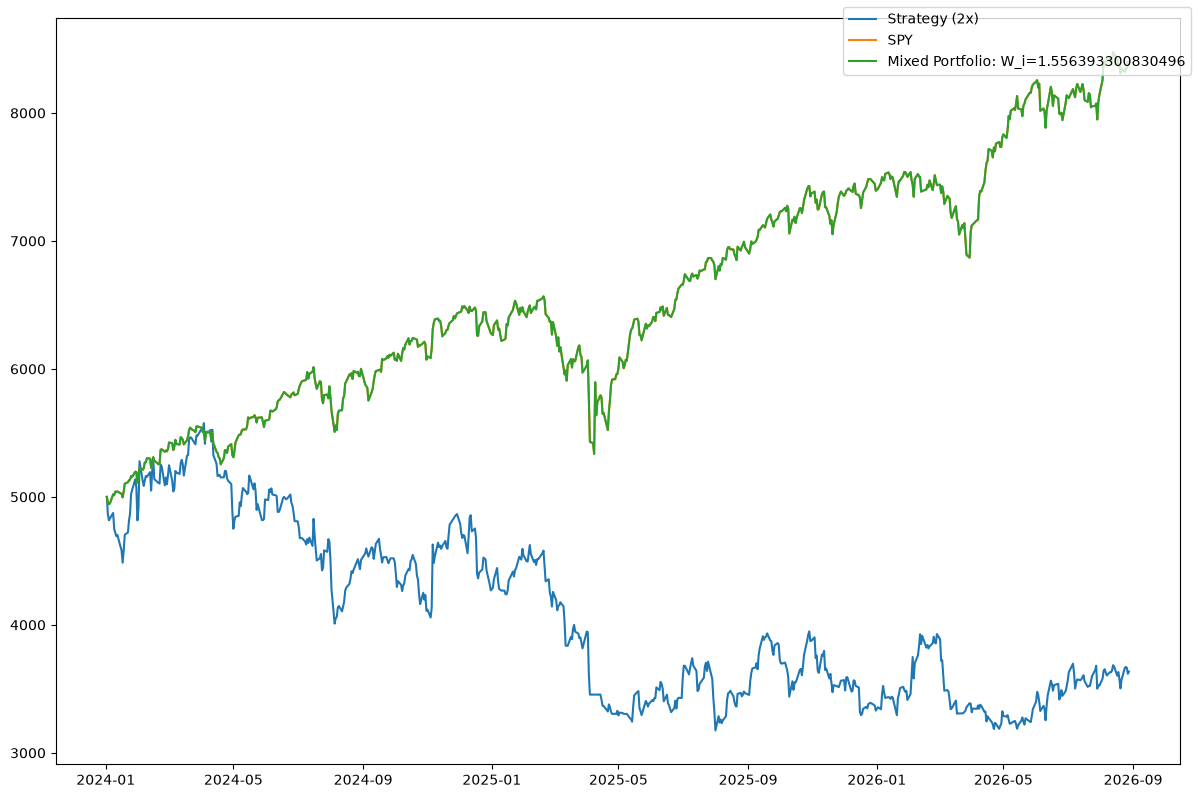

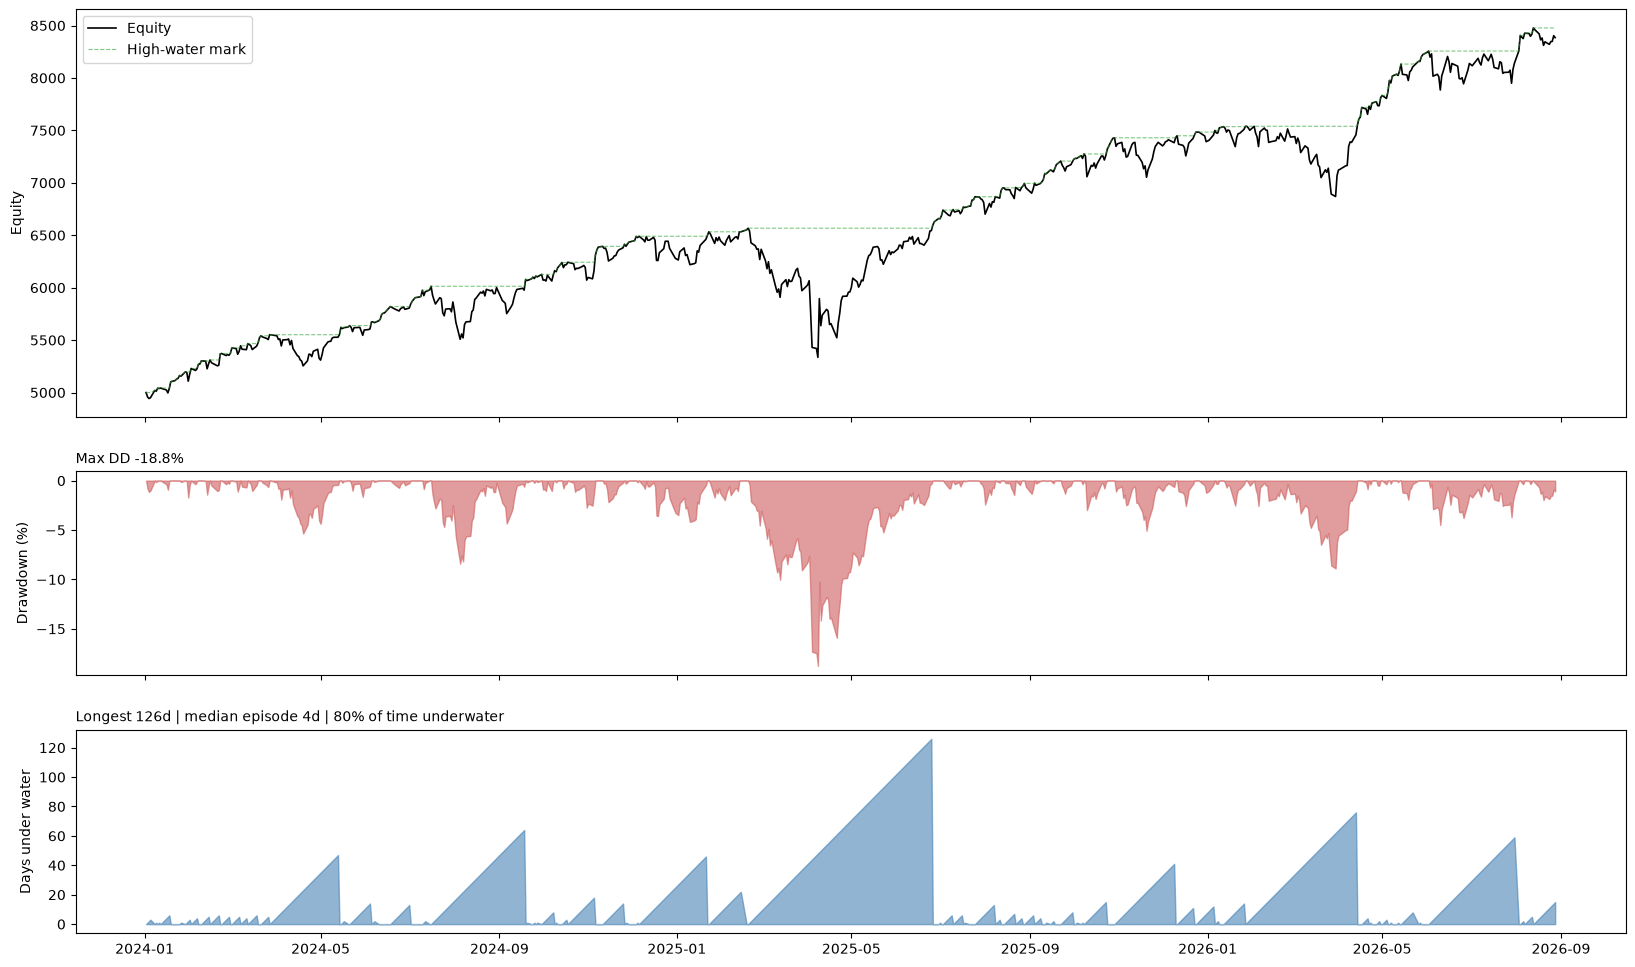

In [41]:
df = test_data

trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = 'Out-of-Sample Performance: Strategy (2x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)

# NO HEATMAP SPIKE (FULL)

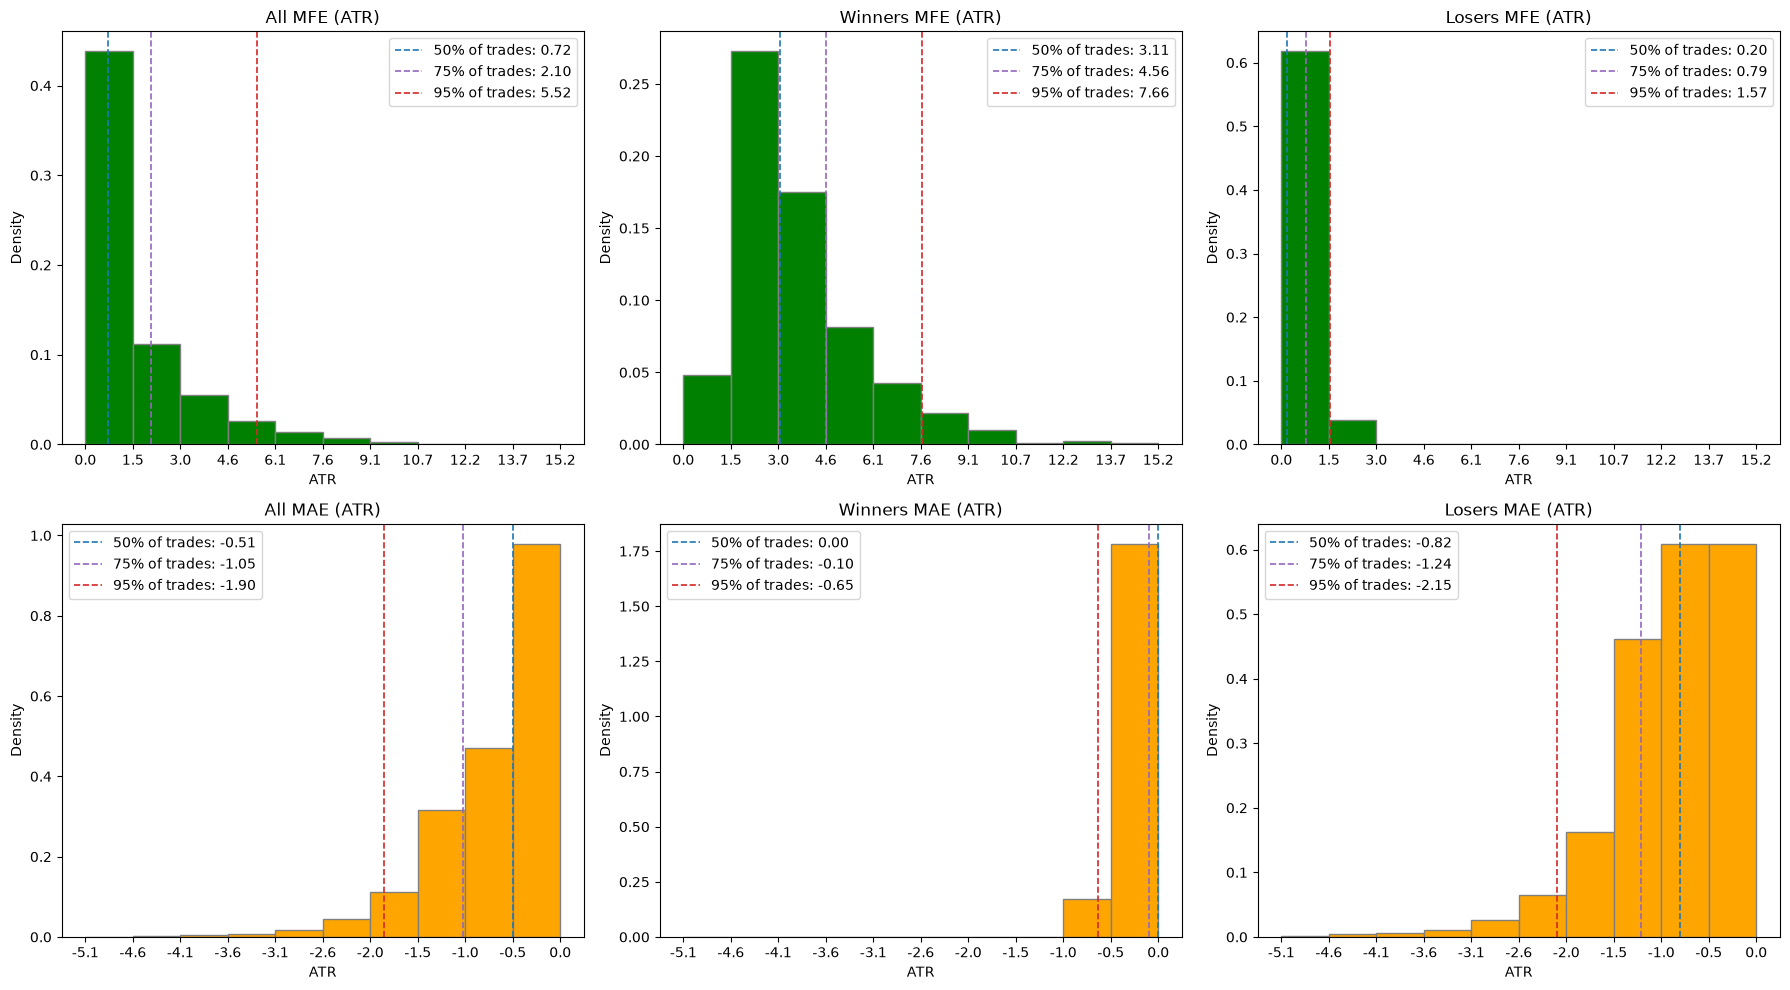

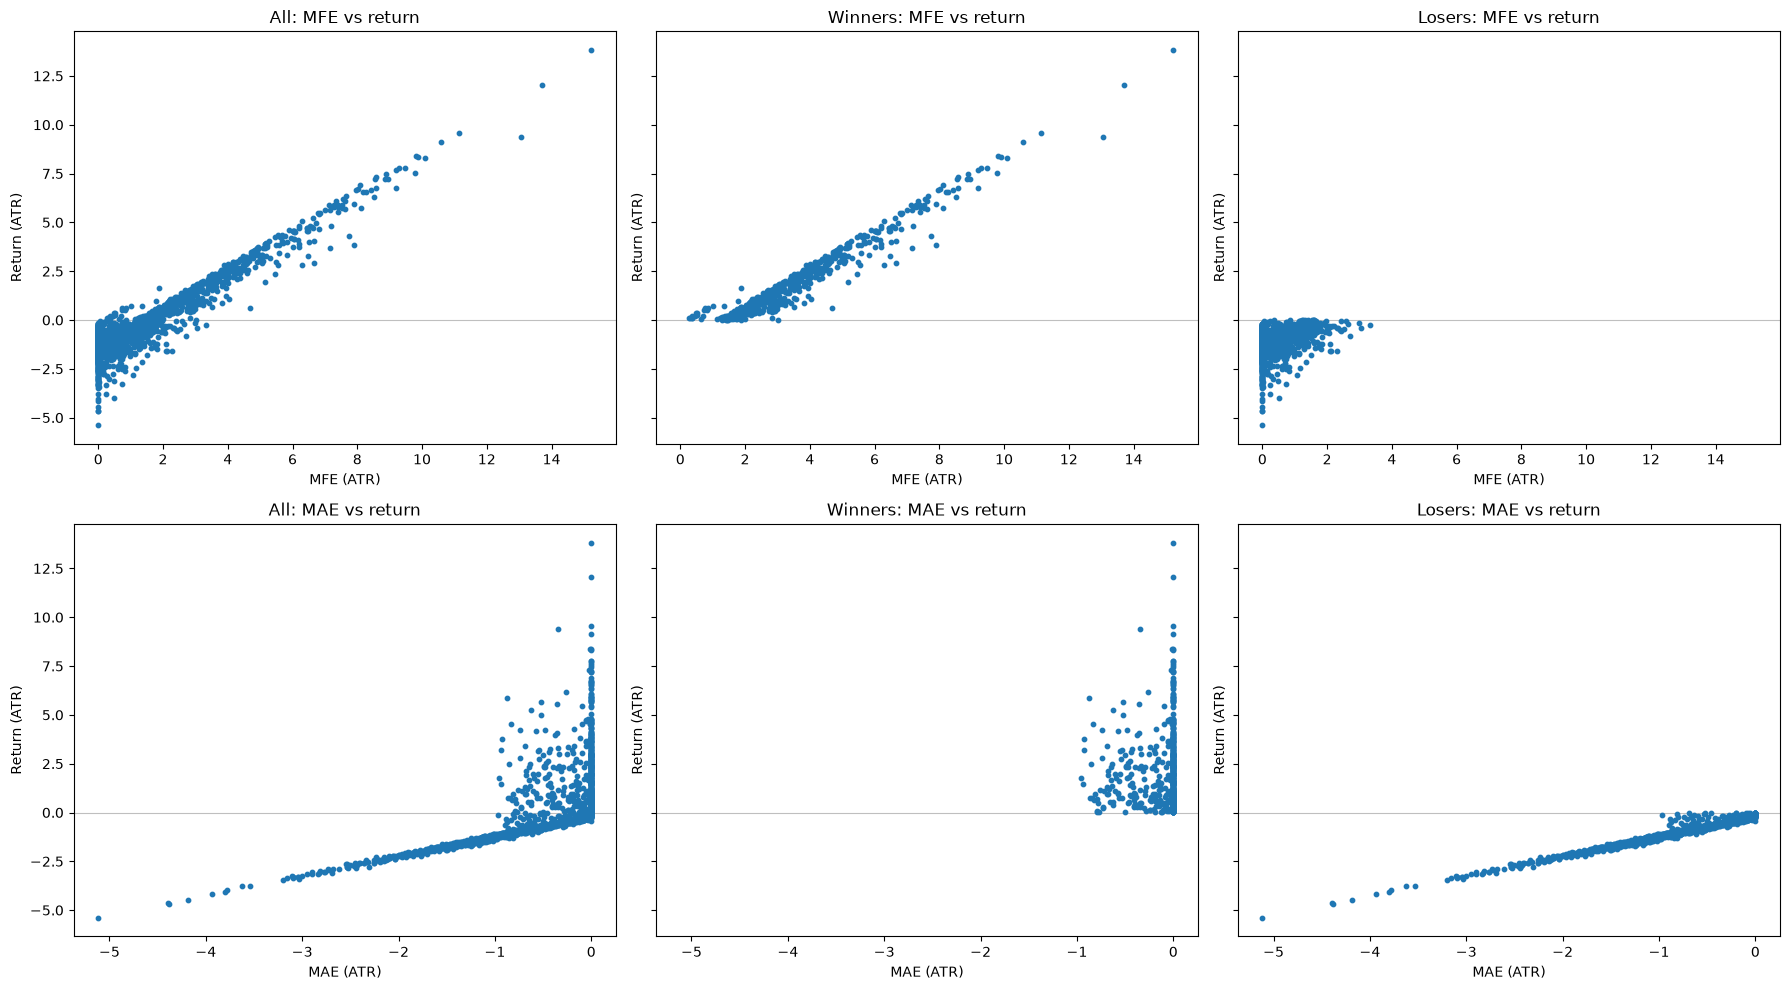

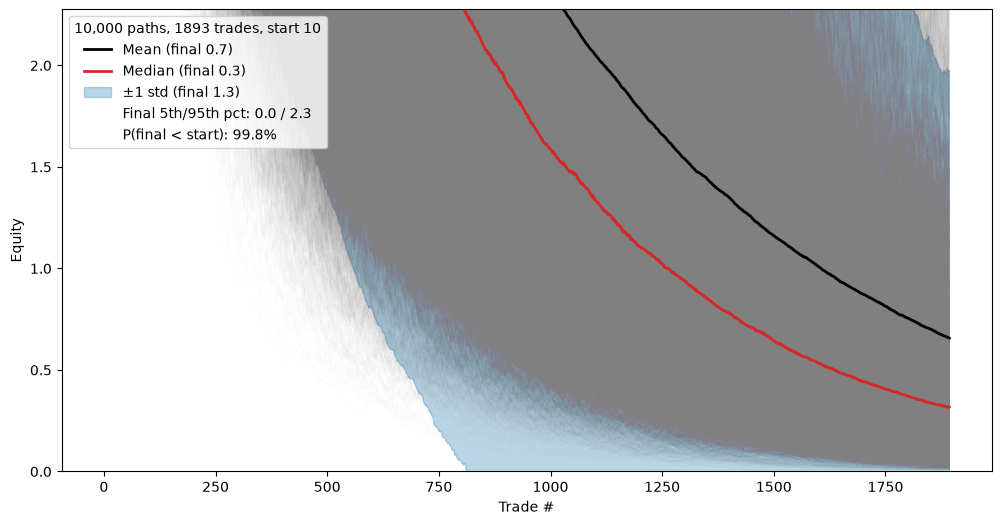

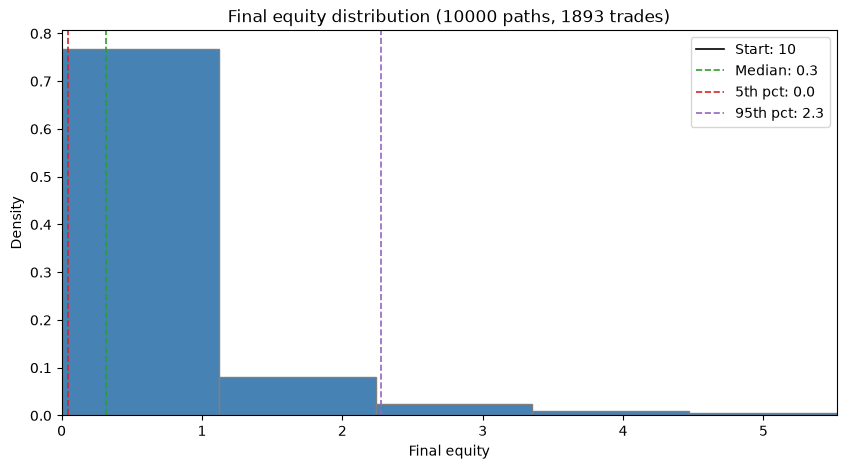

P(loss): 99.8%


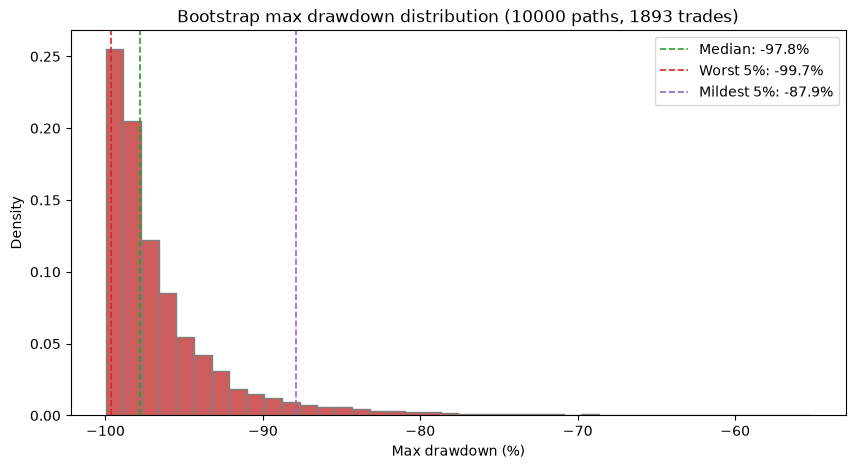

P(maxDD worse than -20%): 100.0%
MaxDD -80.1% on 2025-08-01 | Longest underwater 3136d | Median episode 4d | Time underwater 99% | Currently 3136d under


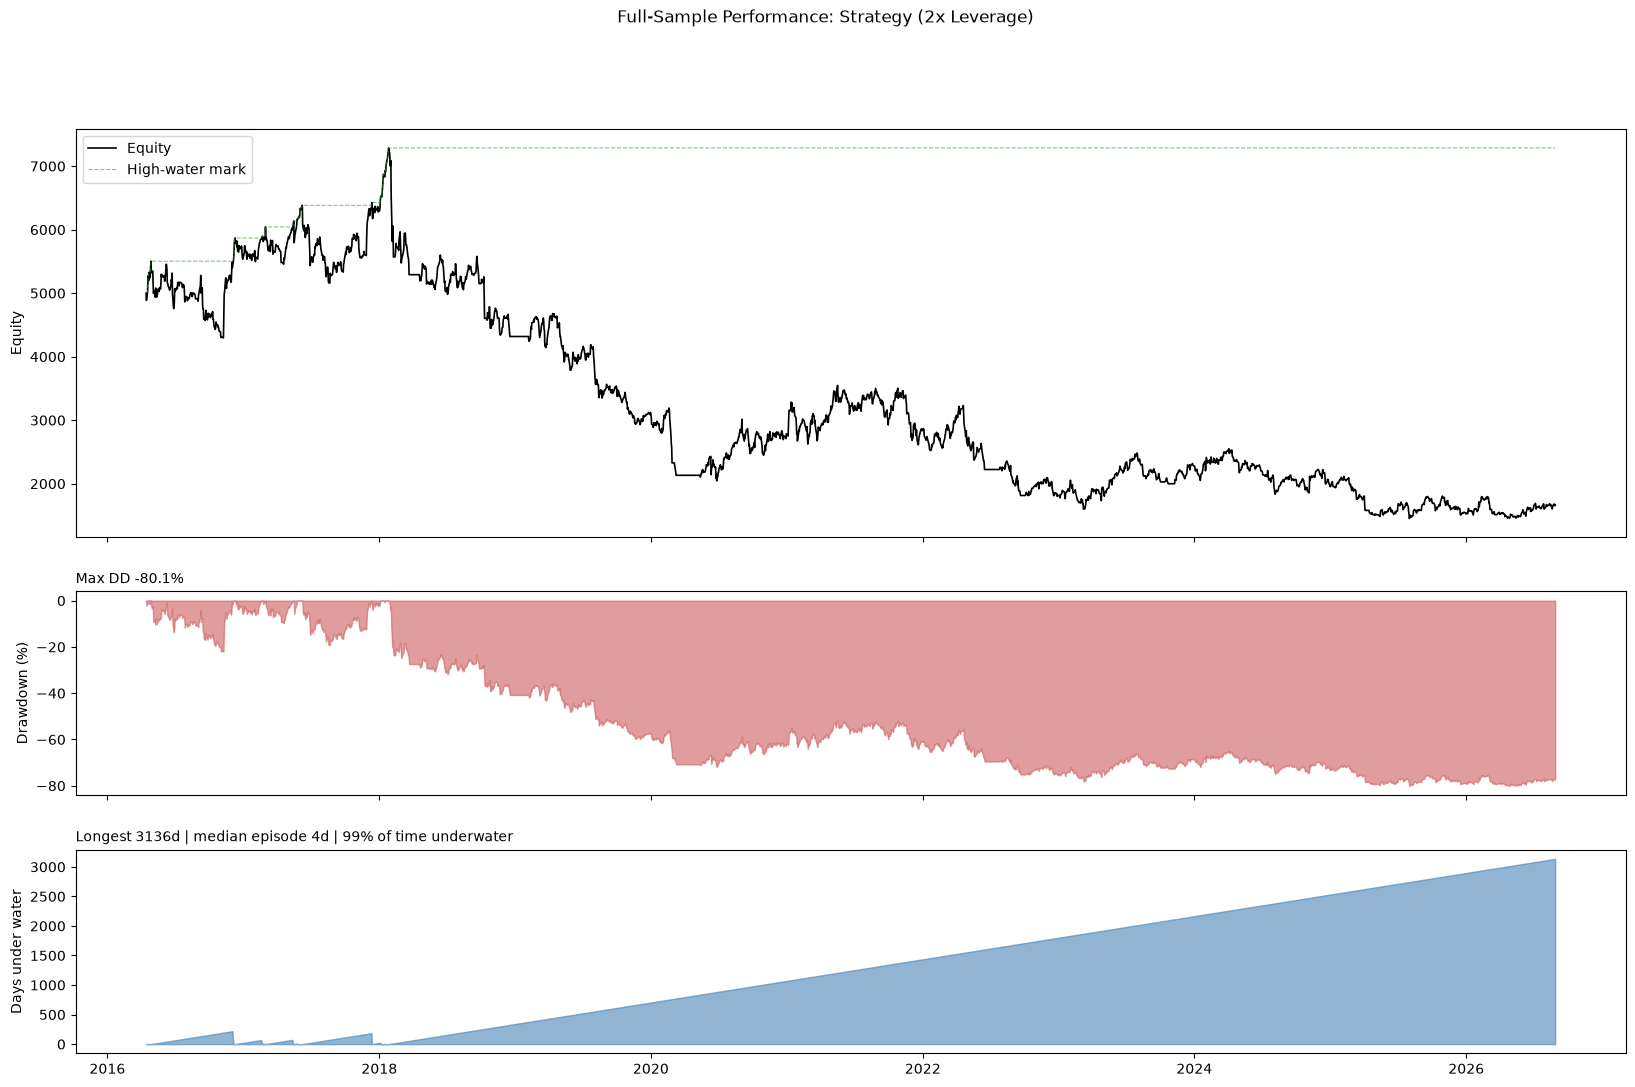

Total return (%)             -66.76
CAGR (%)                     -10.08
Ann. vol (%)                  29.89
Sharpe                        -0.21
Sortino                       -0.27
Max DD (%)                   -80.08
Calmar                        -0.13
Max DD duration (d)         3136.00
Longest underwater (d)      3136.00
Time underwater (%)           98.62
Signals                     1893.00
Trades filled               1159.00
Skipped, no capacity (%)      38.77
Win rate (%)                  32.36
Profit factor                  0.85
Payoff (avg W / avg L)         1.77
Expectancy (R)                -0.03
Days in market (%)            92.45
Peak leverage (x)              2.00
rho = 0.5401918257404151
S_i = 0.8907276907798369
rho*S_p = -0.11095033259303878
W_i = 1.6873496303438182
                          Strategy     SPY     Mix
Ann. vol (%)                 29.89   17.77   17.77
CAGR (%)                    -10.08   15.27   15.27
Calmar                       -0.13    0.45    0.45
Days i

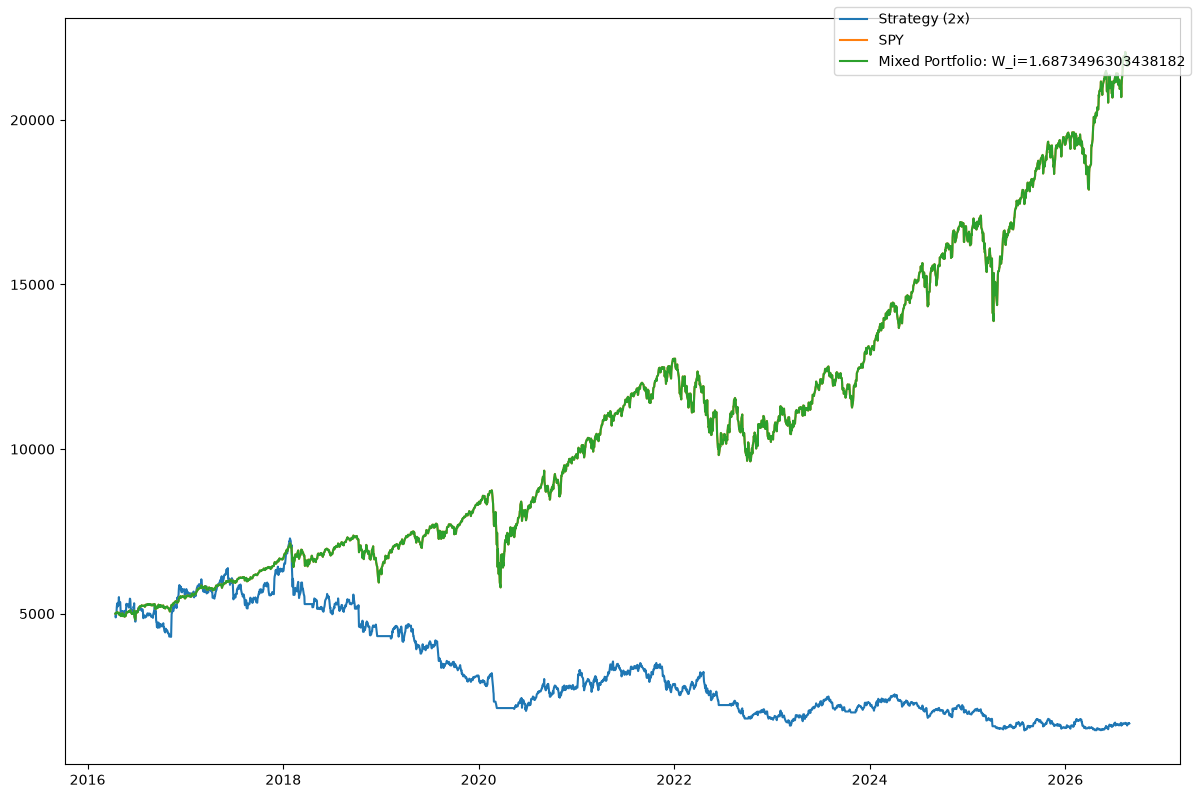

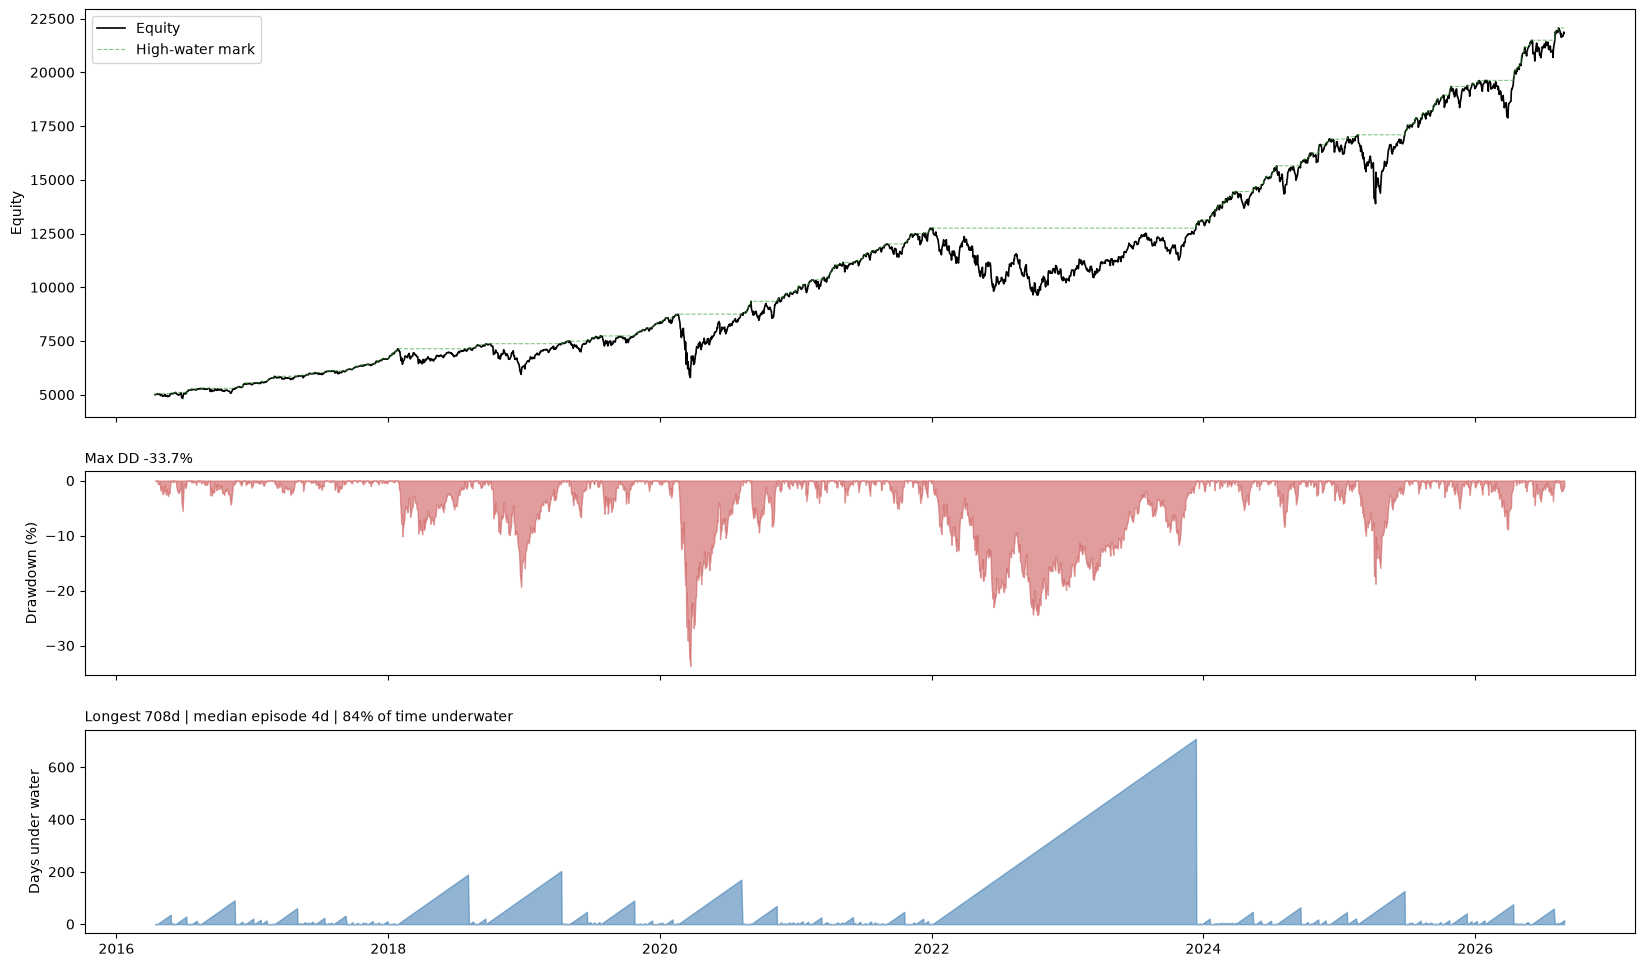

In [42]:
df = all_data

trades,summary = bf.per_trade_backtester(df,entry_fn,exit_fn,COST_BSP)
# display(trades)
# display(summary)

pf.both_plots(trades)

N_PATHS, L, START = 10000, len(trades), 10
pf.plot_mc_sim(trades,N_PATHS,L,START)

t, daily = bf.portfolio_backtester(trades, prices, risk=RISK, atr_mult=TRAIL_ATR, max_lev=MAX_LEVERAGE,whole=False)
yrs = (daily.index[-1] - daily.index[0]).days / 365.25
pf.dd_plot(daily, title = 'Full-Sample Performance: Strategy (2x Leverage)')
stats = bf.perf_stats(daily, t, rf=0.0)      # set rf to an annual rate, e.g. 0.04
print(stats.round(2).to_string())

bf.SPY_combo(daily,t,train_weight=train_W_i,is_train=False)